Libraries loaded successfully.
Upload these 3 files:
1. train(1).csv
2. val(1).csv
3. test(1).csv


Saving val.csv to val.csv
Saving test.csv to test.csv
Saving train.csv to train.csv

Uploaded files:
 - val.csv
 - test.csv
 - train.csv

Files selected:
Train: train.csv
Validation: val.csv
Test: test.csv

================ DATASET SHAPES ================
Train      : (2871, 2)
Validation : (354, 2)
Test       : (355, 2)

================ COLUMNS ================
Train columns: ['text', 'label']
Validation columns: ['text', 'label']
Test columns: ['text', 'label']

Required columns found: text, label

================ LABEL MAPPING ================
0 → Against
1 → Favour
2 → None

================ MISSING VALUES ================

Train
text     0
label    0
dtype: int64

Validation
text     0
label    0
dtype: int64

Test
text     0
label    0
dtype: int64

================ DUPLICATES ================
Train:
Duplicate rows : 0
Duplicate texts: 0
Validation:
Duplicate rows : 0
Duplicate texts: 0
Test:
Duplicate rows : 0
Duplicate texts: 0

================ LABEL DISTRIBUTION ===========

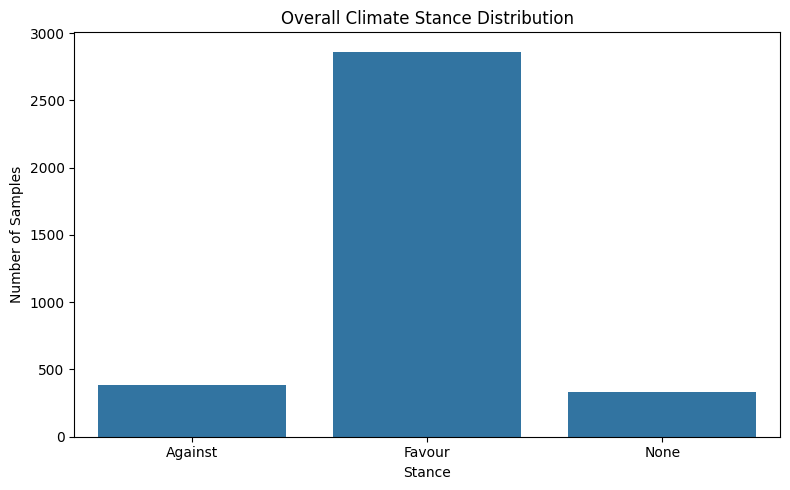

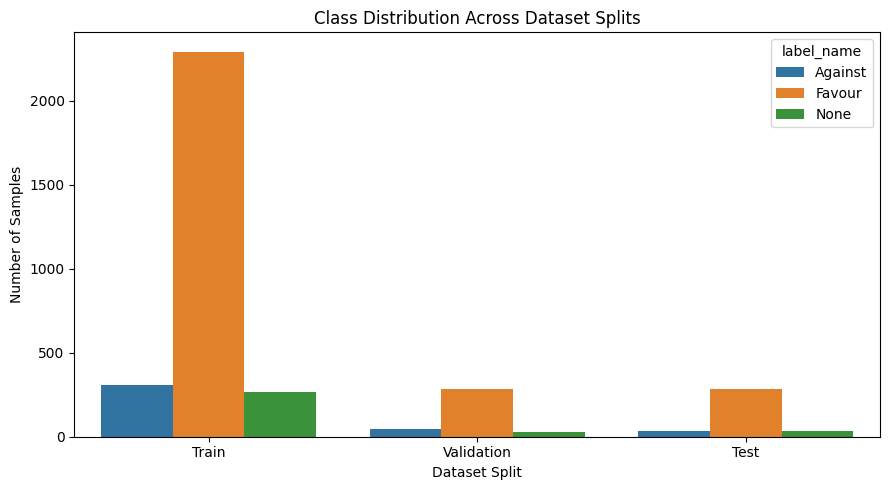

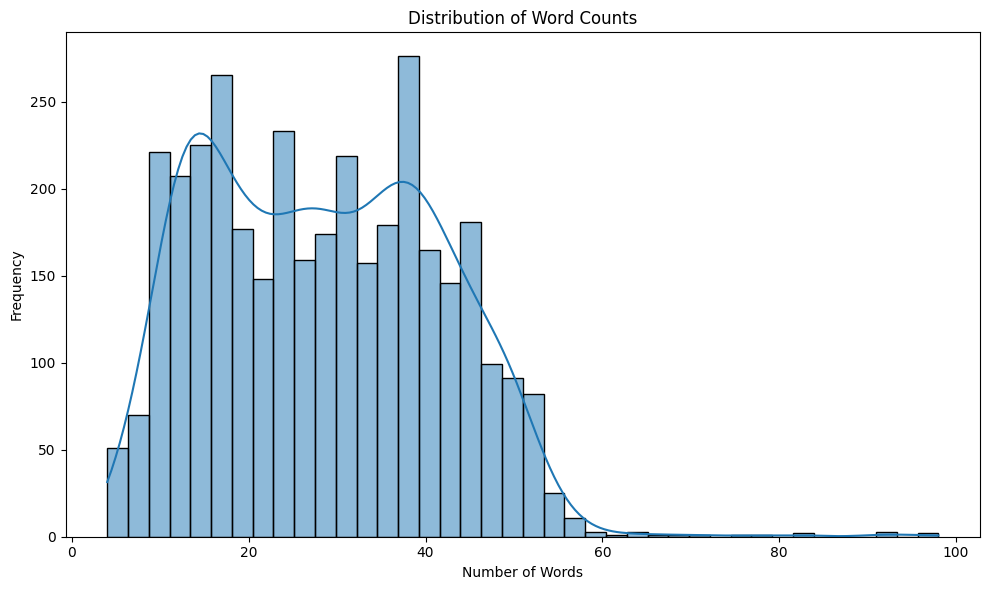

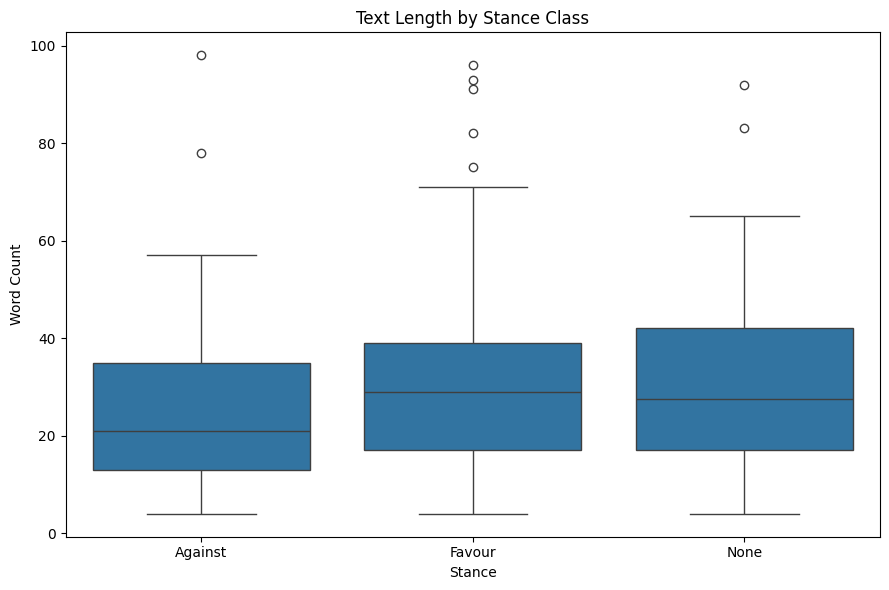

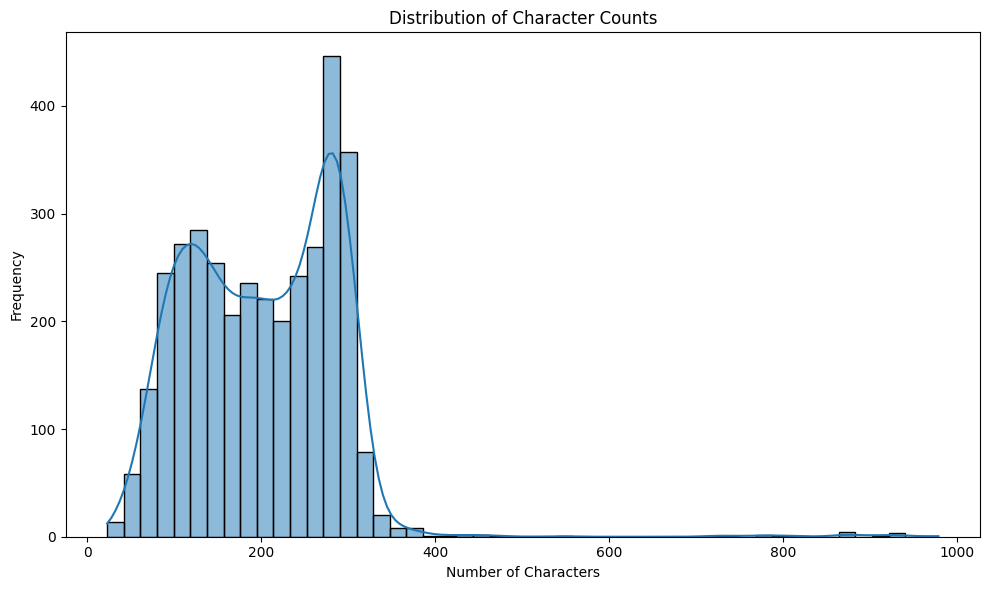


================ SOCIAL MEDIA FEATURES BY CLASS ================
            url_count  mention_count  hashtag_count  exclamation_count  \
label_name                                                               
Against         0.597          1.450          1.574              0.194   
Favour          0.802          1.170          1.919              0.200   
None            0.485          1.945          0.918              0.339   

            question_count  
label_name                  
Against              0.302  
Favour               0.167  
None                 0.258  


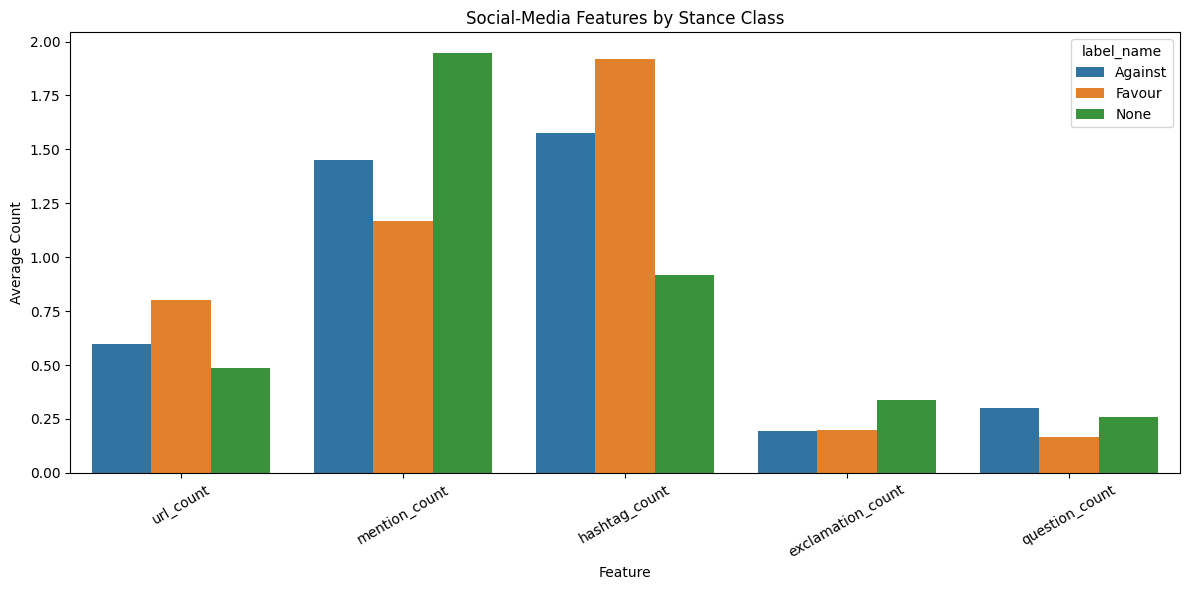


================ NON-ASCII ANALYSIS ================
label_name
Against    0.612
Favour     0.711
None       0.636
Name: non_ascii_count, dtype: float64

================ SOCIAL MEDIA PRESENCE ================
            Has URL (%)  Has Mention (%)  Has Hashtag (%)
label_name                                               
Against           53.75            52.20            43.93
Favour            67.55            50.79            56.58
None              42.42            61.82            33.33

================ MOST COMMON WORDS ================
            Word  Frequency
              to       2640
         climate       2259
          change       1942
              of       1901
              is       1572
              in       1316
   climatechange       1292
              on        926
              it        874
              we        818
          global        526
              be        461
              as        450
         warming        429
             amp        42

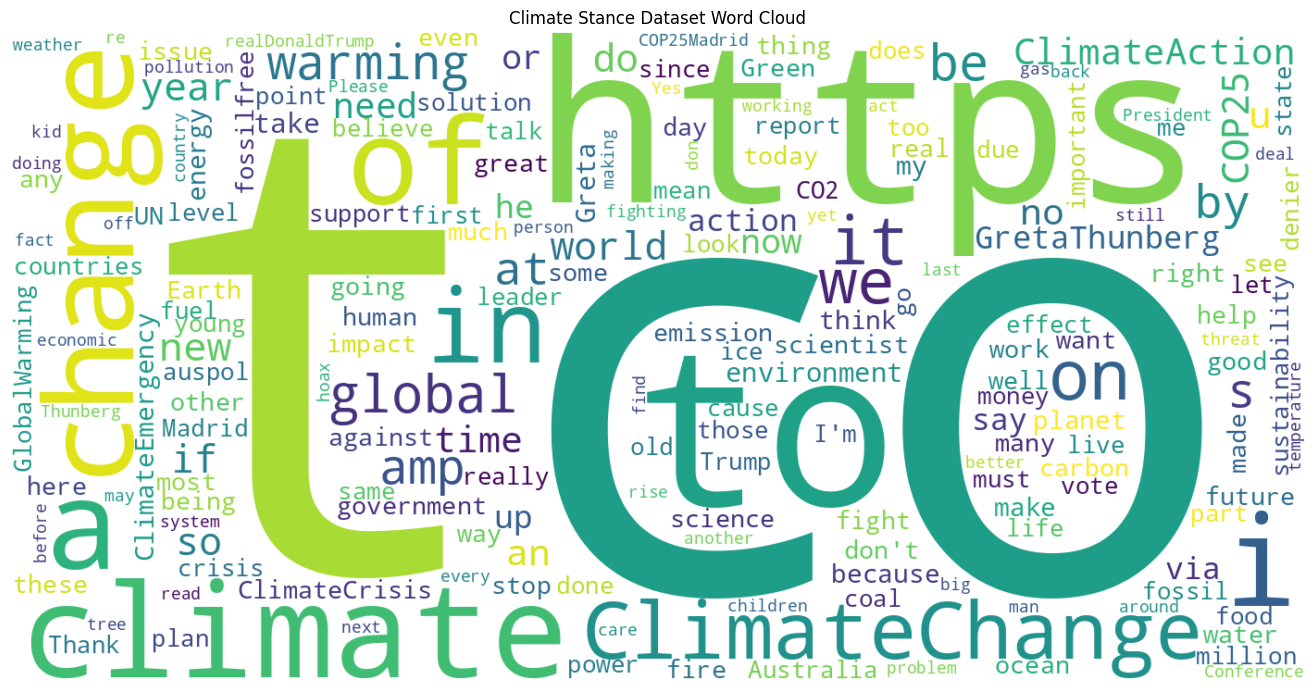


========== AGAINST WORDS ==========
         Word  Frequency
      climate        213
           to        203
       change        187
           is        160
           of        157
climatechange        133
           in         93
           it         91
           on         80
       global         70
      warming         70
           as         47
           we         47
           be         44
           he         44
           so         32
           no         32
          amp         29
           at         29
           by         28
           or         24
           an         24
           if         23
           do         21
          don         20
           up         20
        think         19
        greta         19
          via         19
          new         19

========== FAVOUR WORDS ==========
         Word  Frequency
           to       2226
      climate       1808
           of       1558
       change       1553
           is       1179
  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CSET346 — INDIC CLIMATE STANCE CHALLENGE
# PHASE 1: COMPLETE DATASET EDA
# ============================================================

# =========================
# 1. INSTALL REQUIREMENTS
# =========================
!pip -q install pandas numpy matplotlib seaborn wordcloud openpyxl

# =========================
# 2. IMPORT LIBRARIES
# =========================
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from wordcloud import WordCloud
from google.colab import files

print("Libraries loaded successfully.")

# =========================
# 3. CREATE RESULT FOLDERS
# =========================
os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

# =========================
# 4. UPLOAD DATASETS
# =========================
print("Upload these 3 files:")
print("1. train(1).csv")
print("2. val(1).csv")
print("3. test(1).csv")

uploaded = files.upload()

print("\nUploaded files:")
for f in uploaded:
    print(" -", f)

# =========================
# 5. FIND CSV FILES
# =========================
csv_files = [f for f in uploaded.keys() if f.lower().endswith(".csv")]

if len(csv_files) < 3:
    raise ValueError("Please upload train, validation and test CSV files.")

def find_file(keyword):
    for f in csv_files:
        if keyword.lower() in f.lower():
            return f
    return None

train_file = find_file("train")
val_file = find_file("val")
test_file = find_file("test")

if train_file is None or val_file is None or test_file is None:
    print("\nCould not automatically identify all files.")
    print("Available files:", csv_files)
    raise ValueError("Rename files clearly as train, val and test and rerun.")

print("\nFiles selected:")
print("Train:", train_file)
print("Validation:", val_file)
print("Test:", test_file)

# =========================
# 6. LOAD DATA
# =========================
train = pd.read_csv(train_file)
val = pd.read_csv(val_file)
test = pd.read_csv(test_file)

print("\n================ DATASET SHAPES ================")
print("Train      :", train.shape)
print("Validation :", val.shape)
print("Test       :", test.shape)

# =========================
# 7. BASIC STRUCTURE
# =========================
print("\n================ COLUMNS ================")
print("Train columns:", train.columns.tolist())
print("Validation columns:", val.columns.tolist())
print("Test columns:", test.columns.tolist())

required_columns = {"text", "label"}

for name, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} is missing columns: {missing}"
        )

print("\nRequired columns found: text, label")

# =========================
# 8. LABEL MAPPING
# =========================
# Dataset-derived mapping established from inspection
label_map = {
    0: "Against",
    1: "Favour",
    2: "None"
}

for df in [train, val, test]:
    df["label_name"] = df["label"].map(label_map)

unknown_labels = set(
    pd.concat([train["label"], val["label"], test["label"]]).unique()
) - set(label_map.keys())

if unknown_labels:
    print("WARNING: Unknown labels found:", unknown_labels)

print("\n================ LABEL MAPPING ================")
for k, v in label_map.items():
    print(f"{k} → {v}")

# =========================
# 9. MISSING VALUES
# =========================
print("\n================ MISSING VALUES ================")

for name, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{name}")
    print(df[["text", "label"]].isnull().sum())

# =========================
# 10. DUPLICATES
# =========================
print("\n================ DUPLICATES ================")

for name, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"{name}:")
    print("Duplicate rows :", df.duplicated().sum())
    print("Duplicate texts:", df["text"].duplicated().sum())

# =========================
# 11. LABEL DISTRIBUTION
# =========================
print("\n================ LABEL DISTRIBUTION ================")

def label_distribution(df, name):
    counts = df["label"].value_counts().sort_index()
    percentages = counts / len(df) * 100

    result = pd.DataFrame({
        "Label": counts.index,
        "Class": [label_map.get(x, "Unknown") for x in counts.index],
        "Count": counts.values,
        "Percentage": percentages.values
    })

    print("\n", name)
    print(result.to_string(index=False))

    return result

train_dist = label_distribution(train, "TRAIN")
val_dist = label_distribution(val, "VALIDATION")
test_dist = label_distribution(test, "TEST")

train_dist.to_csv(
    "results/tables/train_label_distribution.csv",
    index=False
)

val_dist.to_csv(
    "results/tables/validation_label_distribution.csv",
    index=False
)

test_dist.to_csv(
    "results/tables/test_label_distribution.csv",
    index=False
)

# =========================
# 12. COMBINED DATASET
# =========================
train["split"] = "Train"
val["split"] = "Validation"
test["split"] = "Test"

all_data = pd.concat(
    [train, val, test],
    ignore_index=True
)

print("\n================ TOTAL DATA ================")
print("Total samples:", len(all_data))
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

# =========================
# 13. TEXT LENGTH FEATURES
# =========================

def add_text_features(df):

    df["text"] = df["text"].astype(str)

    df["char_count"] = df["text"].str.len()

    df["word_count"] = df["text"].apply(
        lambda x: len(x.split())
    )

    df["sentence_count"] = df["text"].apply(
        lambda x: max(1, len(re.findall(r"[.!?]+", x)))
    )

    df["url_count"] = df["text"].apply(
        lambda x: len(
            re.findall(r"https?://\S+|www\.\S+", x)
        )
    )

    df["mention_count"] = df["text"].apply(
        lambda x: len(re.findall(r"@\w+", x))
    )

    df["hashtag_count"] = df["text"].apply(
        lambda x: len(re.findall(r"#\w+", x))
    )

    df["exclamation_count"] = df["text"].str.count("!")

    df["question_count"] = df["text"].str.count(r"\?")

    df["uppercase_count"] = df["text"].apply(
        lambda x: sum(c.isupper() for c in x)
    )

    df["digit_count"] = df["text"].apply(
        lambda x: sum(c.isdigit() for c in x)
    )

    df["non_ascii_count"] = df["text"].apply(
        lambda x: sum(ord(c) > 127 for c in x)
    )

    df["emoji_like"] = df["text"].apply(
        lambda x: bool(
            re.search(
                r"[\U0001F300-\U0001FAFF]",
                x
            )
        )
    )

    return df

all_data = add_text_features(all_data)

# =========================
# 14. TEXT STATISTICS
# =========================
print("\n================ TEXT STATISTICS ================")

text_stats = all_data[
    [
        "char_count",
        "word_count",
        "sentence_count",
        "url_count",
        "mention_count",
        "hashtag_count",
        "exclamation_count",
        "question_count",
        "uppercase_count",
        "digit_count",
        "non_ascii_count"
    ]
].describe().T

print(text_stats)

text_stats.to_csv(
    "results/tables/text_statistics.csv"
)

# =========================
# 15. STATISTICS BY SPLIT
# =========================
print("\n================ STATISTICS BY SPLIT ================")

split_stats = all_data.groupby("split")[
    [
        "char_count",
        "word_count",
        "url_count",
        "mention_count",
        "hashtag_count",
        "non_ascii_count"
    ]
].mean().round(2)

print(split_stats)

split_stats.to_csv(
    "results/tables/split_statistics.csv"
)

# =========================
# 16. STATISTICS BY CLASS
# =========================
print("\n================ STATISTICS BY CLASS ================")

class_stats = all_data.groupby("label_name")[
    [
        "char_count",
        "word_count",
        "url_count",
        "mention_count",
        "hashtag_count",
        "non_ascii_count"
    ]
].mean().round(2)

print(class_stats)

class_stats.to_csv(
    "results/tables/class_statistics.csv"
)

# =========================
# 17. CLASS DISTRIBUTION GRAPH
# =========================
plt.figure(figsize=(8, 5))

sns.countplot(
    data=all_data,
    x="label_name",
    order=["Against", "Favour", "None"]
)

plt.title("Overall Climate Stance Distribution")
plt.xlabel("Stance")
plt.ylabel("Number of Samples")
plt.tight_layout()

plt.savefig(
    "results/figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 18. CLASS DISTRIBUTION BY SPLIT
# =========================
plt.figure(figsize=(9, 5))

sns.countplot(
    data=all_data,
    x="split",
    hue="label_name",
    hue_order=["Against", "Favour", "None"]
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Samples")
plt.tight_layout()

plt.savefig(
    "results/figures/class_distribution_by_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 19. WORD COUNT DISTRIBUTION
# =========================
plt.figure(figsize=(10, 6))

sns.histplot(
    data=all_data,
    x="word_count",
    bins=40,
    kde=True
)

plt.title("Distribution of Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "results/figures/word_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 20. WORD COUNT BY CLASS
# =========================
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=all_data,
    x="label_name",
    y="word_count",
    order=["Against", "Favour", "None"]
)

plt.title("Text Length by Stance Class")
plt.xlabel("Stance")
plt.ylabel("Word Count")
plt.tight_layout()

plt.savefig(
    "results/figures/word_count_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 21. CHARACTER COUNT
# =========================
plt.figure(figsize=(10, 6))

sns.histplot(
    data=all_data,
    x="char_count",
    bins=50,
    kde=True
)

plt.title("Distribution of Character Counts")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "results/figures/character_count_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 22. SOCIAL MEDIA FEATURES
# =========================
feature_means = all_data.groupby("label_name")[
    [
        "url_count",
        "mention_count",
        "hashtag_count",
        "exclamation_count",
        "question_count"
    ]
].mean()

print("\n================ SOCIAL MEDIA FEATURES BY CLASS ================")
print(feature_means.round(3))

feature_means.to_csv(
    "results/tables/social_media_features_by_class.csv"
)

# =========================
# 23. SOCIAL MEDIA FEATURE GRAPH
# =========================
plot_df = feature_means.reset_index()

plot_df = plot_df.melt(
    id_vars="label_name",
    var_name="Feature",
    value_name="Average"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Feature",
    y="Average",
    hue="label_name"
)

plt.title("Social-Media Features by Stance Class")
plt.xlabel("Feature")
plt.ylabel("Average Count")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "results/figures/social_media_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 24. NON-ASCII / POSSIBLE MULTILINGUAL TEXT
# =========================
non_ascii_summary = all_data.groupby("label_name")[
    "non_ascii_count"
].mean()

print("\n================ NON-ASCII ANALYSIS ================")
print(non_ascii_summary.round(3))

# =========================
# 25. URL / HASHTAG / MENTION PRESENCE
# =========================
all_data["has_url"] = all_data["url_count"] > 0
all_data["has_mention"] = all_data["mention_count"] > 0
all_data["has_hashtag"] = all_data["hashtag_count"] > 0

presence_table = pd.DataFrame({
    "Has URL (%)":
        all_data.groupby("label_name")["has_url"].mean() * 100,

    "Has Mention (%)":
        all_data.groupby("label_name")["has_mention"].mean() * 100,

    "Has Hashtag (%)":
        all_data.groupby("label_name")["has_hashtag"].mean() * 100
}).round(2)

print("\n================ SOCIAL MEDIA PRESENCE ================")
print(presence_table)

presence_table.to_csv(
    "results/tables/social_media_presence.csv"
)

# =========================
# 26. MOST COMMON WORDS
# =========================

def clean_text(text):

    text = text.lower()

    # remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # remove mentions
    text = re.sub(
        r"@\w+",
        " ",
        text
    )

    # remove hashtags symbol but retain word
    text = re.sub(
        r"#",
        "",
        text
    )

    # keep alphabetic words
    words = re.findall(
        r"[a-zA-Z]{2,}",
        text
    )

    return words


stopwords = {
    "the","and","for","that","this","with","are","was",
    "from","have","has","had","you","your","they","their",
    "will","would","could","should","about","there","what",
    "when","where","which","who","why","how","not","but",
    "our","out","all","can","its","into","than","then",
    "them","his","her","she","him","been","were","also",
    "more","one","two","very","just","only","over","get",
    "got","like","people","know","use","using"
}

def common_words(df, n=30):

    counter = Counter()

    for text in df["text"]:
        words = clean_text(str(text))

        words = [
            w for w in words
            if w not in stopwords
        ]

        counter.update(words)

    return counter.most_common(n)

overall_words = common_words(all_data, 50)

common_words_df = pd.DataFrame(
    overall_words,
    columns=["Word", "Frequency"]
)

print("\n================ MOST COMMON WORDS ================")
print(common_words_df.to_string(index=False))

common_words_df.to_csv(
    "results/tables/most_common_words.csv",
    index=False
)

# =========================
# 27. WORDCLOUD
# =========================
text_for_wc = " ".join(
    all_data["text"].astype(str).tolist()
)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    stopwords=stopwords,
    collocations=False
).generate(text_for_wc)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Climate Stance Dataset Word Cloud")
plt.tight_layout()

plt.savefig(
    "results/figures/wordcloud.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# 28. CLASS-SPECIFIC WORDS
# =========================
for class_name in ["Against", "Favour", "None"]:

    subset = all_data[
        all_data["label_name"] == class_name
    ]

    words = common_words(subset, 30)

    df_words = pd.DataFrame(
        words,
        columns=["Word", "Frequency"]
    )

    print(f"\n========== {class_name.upper()} WORDS ==========")
    print(df_words.to_string(index=False))

    safe_name = class_name.lower()

    df_words.to_csv(
        f"results/tables/{safe_name}_common_words.csv",
        index=False
    )

# =========================
# 29. LEAKAGE CHECK
# =========================
print("\n================ DATA LEAKAGE CHECK ================")

train_texts = set(train["text"].astype(str))
val_texts = set(val["text"].astype(str))
test_texts = set(test["text"].astype(str))

train_val_overlap = train_texts.intersection(val_texts)
train_test_overlap = train_texts.intersection(test_texts)
val_test_overlap = val_texts.intersection(test_texts)

print(
    "Train ↔ Validation:",
    len(train_val_overlap)
)

print(
    "Train ↔ Test:",
    len(train_test_overlap)
)

print(
    "Validation ↔ Test:",
    len(val_test_overlap)
)

leakage_summary = pd.DataFrame({
    "Comparison": [
        "Train-Validation",
        "Train-Test",
        "Validation-Test"
    ],
    "Exact_Text_Overlap": [
        len(train_val_overlap),
        len(train_test_overlap),
        len(val_test_overlap)
    ]
})

leakage_summary.to_csv(
    "results/tables/leakage_check.csv",
    index=False
)

# =========================
# 30. RANDOM EXAMPLES
# =========================
print("\n================ RANDOM EXAMPLES BY CLASS ================")

for class_name in ["Against", "Favour", "None"]:

    print(f"\n\n========== {class_name.upper()} ==========")

    subset = all_data[
        all_data["label_name"] == class_name
    ]

    examples = subset.sample(
        min(5, len(subset)),
        random_state=42
    )

    for i, row in enumerate(
        examples["text"],
        start=1
    ):
        print(f"\n{i}. {row}")

# =========================
# 31. VERY LONG TEXTS
# =========================
print("\n================ LONGEST TEXTS ================")

longest = all_data.nlargest(
    10,
    "word_count"
)[
    ["label_name", "word_count", "text"]
]

print(longest.to_string(index=False))

longest.to_csv(
    "results/tables/longest_texts.csv",
    index=False
)

# =========================
# 32. VERY SHORT TEXTS
# =========================
print("\n================ SHORTEST TEXTS ================")

shortest = all_data.nsmallest(
    10,
    "word_count"
)[
    ["label_name", "word_count", "text"]
]

print(shortest.to_string(index=False))

shortest.to_csv(
    "results/tables/shortest_texts.csv",
    index=False
)

# =========================
# 33. FINAL EDA SUMMARY
# =========================

summary = {
    "Total Samples": len(all_data),
    "Training Samples": len(train),
    "Validation Samples": len(val),
    "Test Samples": len(test),

    "Against Count": int(
        (all_data["label_name"] == "Against").sum()
    ),

    "Favour Count": int(
        (all_data["label_name"] == "Favour").sum()
    ),

    "None Count": int(
        (all_data["label_name"] == "None").sum()
    ),

    "Average Words": round(
        all_data["word_count"].mean(), 2
    ),

    "Median Words": round(
        all_data["word_count"].median(), 2
    ),

    "Average Characters": round(
        all_data["char_count"].mean(), 2
    ),

    "URLs (%)": round(
        all_data["has_url"].mean() * 100, 2
    ),

    "Mentions (%)": round(
        all_data["has_mention"].mean() * 100, 2
    ),

    "Hashtags (%)": round(
        all_data["has_hashtag"].mean() * 100, 2
    ),

    "Non-ASCII (%)": round(
        (all_data["non_ascii_count"] > 0).mean() * 100,
        2
    ),

    "Train-Val Exact Overlap":
        len(train_val_overlap),

    "Train-Test Exact Overlap":
        len(train_test_overlap),

    "Val-Test Exact Overlap":
        len(val_test_overlap)
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

print("\n\n================================================")
print("              FINAL EDA SUMMARY")
print("================================================")
print(summary_df.to_string(index=False))

summary_df.to_csv(
    "results/tables/final_eda_summary.csv",
    index=False
)

# =========================
# 34. SAVE PROCESSED DATA
# =========================
all_data.to_csv(
    "results/tables/combined_eda_data.csv",
    index=False
)

# =========================
# 35. ZIP ALL RESULTS
# =========================
import shutil

shutil.make_archive(
    "CSET346_EDA_Results",
    "zip",
    "results"
)

print("\n================================================")
print("EDA COMPLETE!")
print("================================================")

print("\nGenerated:")
print("✓ Dataset statistics")
print("✓ Label distributions")
print("✓ Text-length analysis")
print("✓ URL analysis")
print("✓ Mention analysis")
print("✓ Hashtag analysis")
print("✓ Non-ASCII analysis")
print("✓ Common-word analysis")
print("✓ Word clouds")
print("✓ Class-specific vocabulary")
print("✓ Duplicate analysis")
print("✓ Leakage analysis")
print("✓ Random examples")
print("✓ Long/short text analysis")
print("✓ CSV tables")
print("✓ PNG figures")

print("\nResults folder: results/")
print("ZIP file: CSET346_EDA_Results.zip")

# =========================
# 36. DOWNLOAD RESULTS
# =========================
files.download("CSET346_EDA_Results.zip")

Libraries loaded successfully.
Upload:
train(1).csv
val(1).csv
test(1).csv


Saving val.csv to val (1).csv
Saving test.csv to test (1).csv
Saving train.csv to train (1).csv

Files detected:
Train: train (1).csv
Validation: val (1).csv
Test: test (1).csv

Dataset shapes:
Train      : (2871, 2)
Validation : (354, 2)
Test       : (355, 2)

Creating TF-IDF features...

TF-IDF shapes:
Train: (2871, 12020)
Val  : (354, 12020)
Test : (355, 12020)

Vocabulary size: 12020

Training Logistic Regression...
Training complete.


VALIDATION RESULTS — TF-IDF + LOGISTIC REGRESSION

Accuracy      : 0.8023
Macro-F1 ⭐   : 0.3213
Weighted-F1   : 0.7194

Per-class results:
Against  | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000 | Support: 44
Favour   | Precision: 0.8040 | Recall: 0.9965 | F1: 0.8899 | Support: 284
None     | Precision: 1.0000 | Recall: 0.0385 | F1: 0.0741 | Support: 26

Classification Report:

              precision    recall  f1-score   support

     Against     0.0000    0.0000    0.0000        44
      Favour     0.8040    0.9965    0.8899       284
        

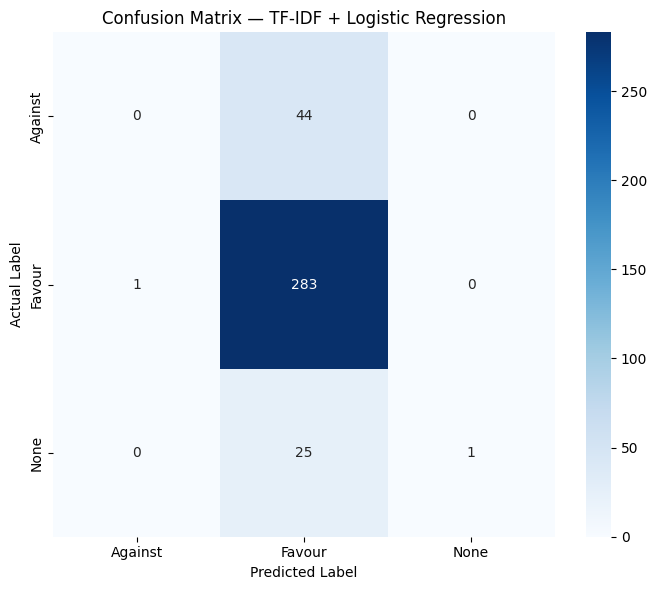


Validation results saved.


VALIDATION ERROR ANALYSIS PREVIEW

Incorrect predictions: 70
Validation accuracy: 0.8023

Sample errors:

----------------------------------------
Actual    : Against
Predicted : Favour
Text      : well some of them HAVE teeth
Its the #mindlessNess that worries me.
No Science
No Free Press
No Climate Change 
No #Constitutional Law
NO #FACTWitnesses ALLOWED To #Testify
No Defense
Just more from the 
#REPugnantNRABLOODMoneyPARTYWHORES
who didnt BOTHER 2 VET #dumBtyCons #TAXES https://t.co/eoLW0ZP20G

----------------------------------------
Actual    : Against
Predicted : Favour
Text      : BBC News - Climate change: Oceans running out of oxygen as temperatures rise https://t.co/nj2Py31TTc

----------------------------------------
Actual    : Against
Predicted : Favour
Text      : Worked some tonight... #instagramartist #art #intuitiveart #intuitiveartist #mentalhealth #PTSD #complexptsd #abuse #instagram #motherearth #bees #environmental #earth #climatechang

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Baseline 1 complete.


In [ ]:
# ============================================================
# CSET346 — BASELINE 1
# TF-IDF + LOGISTIC REGRESSION
# ============================================================

!pip -q install pandas numpy scikit-learn matplotlib seaborn

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries loaded successfully.")

# ============================================================
# 1. UPLOAD DATA
# ============================================================

print("Upload:")
print("train(1).csv")
print("val(1).csv")
print("test(1).csv")

uploaded = files.upload()

csv_files = list(uploaded.keys())

def find_file(keyword):
    for f in csv_files:
        if keyword.lower() in f.lower():
            return f
    return None

train_file = find_file("train")
val_file = find_file("val")
test_file = find_file("test")

print("\nFiles detected:")
print("Train:", train_file)
print("Validation:", val_file)
print("Test:", test_file)

if not all([train_file, val_file, test_file]):
    raise ValueError(
        "Could not identify all three files. "
        "Make sure their names contain train, val and test."
    )

# ============================================================
# 2. LOAD DATA
# ============================================================

train = pd.read_csv(train_file)
val = pd.read_csv(val_file)
test = pd.read_csv(test_file)

print("\nDataset shapes:")
print("Train      :", train.shape)
print("Validation :", val.shape)
print("Test       :", test.shape)

# ============================================================
# 3. VERIFY COLUMNS
# ============================================================

required = {"text", "label"}

for name, df in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} is missing columns: {missing}"
        )

# ============================================================
# 4. CLEAN TEXT
# ============================================================

def clean_text(text):

    text = str(text)

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


train["clean_text"] = train["text"].apply(clean_text)
val["clean_text"] = val["text"].apply(clean_text)
test["clean_text"] = test["text"].apply(clean_text)

# ============================================================
# 5. SEPARATE X AND Y
# ============================================================

X_train = train["clean_text"]
y_train = train["label"]

X_val = val["clean_text"]
y_val = val["label"]

X_test = test["clean_text"]
y_test = test["label"]

# ============================================================
# 6. TF-IDF
# ============================================================

print("\nCreating TF-IDF features...")

vectorizer = TfidfVectorizer(
    lowercase=True,

    # word n-grams
    ngram_range=(1, 2),

    # ignore extremely rare words
    min_df=2,

    # ignore extremely common words
    max_df=0.95,

    # maximum vocabulary
    max_features=50000,

    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_val_tfidf = vectorizer.transform(X_val)

X_test_tfidf = vectorizer.transform(X_test)

print("\nTF-IDF shapes:")
print("Train:", X_train_tfidf.shape)
print("Val  :", X_val_tfidf.shape)
print("Test :", X_test_tfidf.shape)

print(
    "\nVocabulary size:",
    len(vectorizer.vocabulary_)
)

# ============================================================
# 7. TRAIN LOGISTIC REGRESSION
# ============================================================

print("\nTraining Logistic Regression...")

model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

model.fit(
    X_train_tfidf,
    y_train
)

print("Training complete.")

# ============================================================
# 8. VALIDATION PREDICTIONS
# ============================================================

val_pred = model.predict(X_val_tfidf)

# ============================================================
# 9. VALIDATION METRICS
# ============================================================

val_accuracy = accuracy_score(
    y_val,
    val_pred
)

val_macro_f1 = f1_score(
    y_val,
    val_pred,
    average="macro"
)

val_weighted_f1 = f1_score(
    y_val,
    val_pred,
    average="weighted"
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

print("\n")
print("=" * 65)
print("VALIDATION RESULTS — TF-IDF + LOGISTIC REGRESSION")
print("=" * 65)

print(f"\nAccuracy      : {val_accuracy:.4f}")
print(f"Macro-F1 ⭐   : {val_macro_f1:.4f}")
print(f"Weighted-F1   : {val_weighted_f1:.4f}")

print("\nPer-class results:")

class_names = {
    0: "Against",
    1: "Favour",
    2: "None"
}

for i, label in enumerate([0, 1, 2]):

    print(
        f"{class_names[label]:8s} | "
        f"Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | "
        f"F1: {f1[i]:.4f} | "
        f"Support: {support[i]}"
    )

# ============================================================
# 10. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=[
            "Against",
            "Favour",
            "None"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_val,
    val_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Against",
        "Favour",
        "None"
    ],
    yticklabels=[
        "Against",
        "Favour",
        "None"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(
    "Confusion Matrix — TF-IDF + Logistic Regression"
)

plt.tight_layout()

os.makedirs(
    "results/baseline",
    exist_ok=True
)

plt.savefig(
    "results/baseline/lr_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. SAVE VALIDATION RESULTS
# ============================================================

results = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression"
    ],

    "Accuracy": [
        val_accuracy
    ],

    "Macro_F1": [
        val_macro_f1
    ],

    "Weighted_F1": [
        val_weighted_f1
    ],

    "Against_F1": [
        f1[0]
    ],

    "Favour_F1": [
        f1[1]
    ],

    "None_F1": [
        f1[2]
    ]
})

results.to_csv(
    "results/baseline/logistic_regression_validation.csv",
    index=False
)

print("\nValidation results saved.")

# ============================================================
# 13. SAVE PREDICTIONS
# ============================================================

val_predictions = val.copy()

val_predictions["predicted_label"] = val_pred

val_predictions["correct"] = (
    val_predictions["label"]
    ==
    val_predictions["predicted_label"]
)

val_predictions.to_csv(
    "results/baseline/logistic_regression_val_predictions.csv",
    index=False
)

# ============================================================
# 14. ERROR ANALYSIS PREVIEW
# ============================================================

errors = val_predictions[
    val_predictions["correct"] == False
]

print("\n")
print("=" * 65)
print("VALIDATION ERROR ANALYSIS PREVIEW")
print("=" * 65)

print(
    f"\nIncorrect predictions: {len(errors)}"
)

print(
    f"Validation accuracy: "
    f"{val_accuracy:.4f}"
)

print("\nSample errors:")

for _, row in errors.head(15).iterrows():

    print("\n----------------------------------------")

    print(
        "Actual    :",
        class_names.get(
            int(row["label"]),
            row["label"]
        )
    )

    print(
        "Predicted :",
        class_names.get(
            int(row["predicted_label"]),
            row["predicted_label"]
        )
    )

    print(
        "Text      :",
        row["text"]
    )

# ============================================================
# 15. IMPORTANT: DO NOT TOUCH TEST YET
# ============================================================

print("\n")
print("=" * 65)
print("IMPORTANT")
print("=" * 65)

print("""
We have NOT used the test set for model selection.

The test set will be used only after we decide
the final baseline configuration.

Next experiment:
TF-IDF + Linear SVM
""")

# ============================================================
# 16. DOWNLOAD RESULTS
# ============================================================

import shutil

shutil.make_archive(
    "baseline1_logistic_regression",
    "zip",
    "results/baseline"
)

files.download(
    "baseline1_logistic_regression.zip"
)

print("\nBaseline 1 complete.")

Upload:
train(1).csv
val(1).csv
test(1).csv


Saving val.csv to val (2).csv
Saving test.csv to test (2).csv
Saving train.csv to train (2).csv

Detected:
Train: train (2).csv
Validation: val (2).csv
Test: test (2).csv

Shapes:
Train: (2871, 2)
Val  : (354, 2)
Test : (355, 2)

Creating TF-IDF...
Vocabulary size: 12020

Training Linear SVM...
Training complete.


VALIDATION RESULTS — TF-IDF + LINEAR SVM

Accuracy      : 0.8107
Macro-F1 ⭐   : 0.4289
Weighted-F1   : 0.7535

Per-class results:
Against  | Precision: 0.2222 | Recall: 0.0455 | F1: 0.0755 | Support: 44
Favour   | Precision: 0.8260 | Recall: 0.9859 | F1: 0.8989 | Support: 284
None     | Precision: 0.8333 | Recall: 0.1923 | F1: 0.3125 | Support: 26

Classification Report:

              precision    recall  f1-score   support

     Against     0.2222    0.0455    0.0755        44
      Favour     0.8260    0.9859    0.8989       284
        None     0.8333    0.1923    0.3125        26

    accuracy                         0.8107       354
   macro avg     0.6272    0.4079   

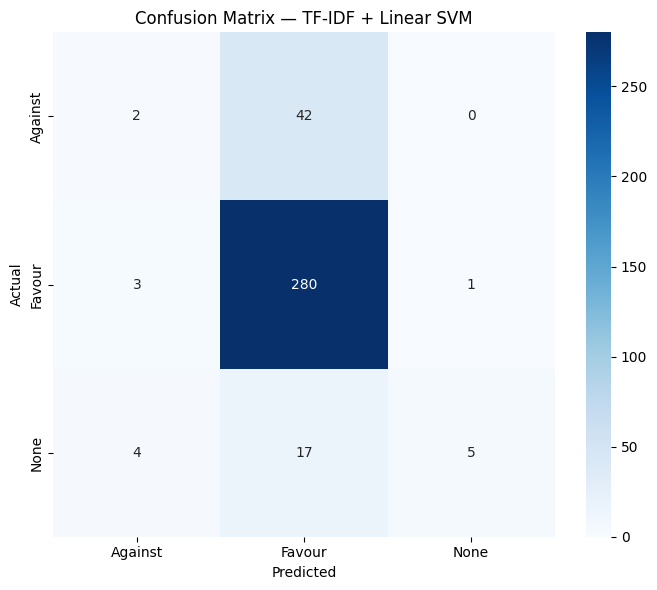



ERROR ANALYSIS PREVIEW

Incorrect predictions: 67

----------------------------------------
Actual: Against
Predicted: Favour
Text: well some of them HAVE teeth
Its the #mindlessNess that worries me.
No Science
No Free Press
No Climate Change 
No #Constitutional Law
NO #FACTWitnesses ALLOWED To #Testify
No Defense
Just more from the 
#REPugnantNRABLOODMoneyPARTYWHORES
who didnt BOTHER 2 VET #dumBtyCons #TAXES https://t.co/eoLW0ZP20G

----------------------------------------
Actual: Favour
Predicted: None
Text: @stumpyspurs Of course he's bottled it. Because he has no answers to any of dozens of lies he is wrapped up in. Why do you think he AND Farage bottled the climate debate too? Because right wing parties a rife with climate change denial. A liar and a coward as a prime minister it is then?

----------------------------------------
Actual: Against
Predicted: Favour
Text: BBC News - Climate change: Oceans running out of oxygen as temperatures rise https://t.co/nj2Py31TTc

---------

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



BASELINE 2 COMPLETE

IMPORTANT:
We still have NOT used the test labels
for model selection.

Next:
Compare LR vs SVM.
Then introduce imbalance-aware methods.



In [ ]:
# ============================================================
# CSET346 — BASELINE 2
# TF-IDF + LINEAR SVM
# ============================================================

!pip -q install pandas numpy scikit-learn matplotlib seaborn

import os
import re
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. UPLOAD DATA
# ============================================================

print("Upload:")
print("train(1).csv")
print("val(1).csv")
print("test(1).csv")

uploaded = files.upload()

uploaded_files = list(uploaded.keys())

def find_file(keyword):
    for f in uploaded_files:
        if keyword.lower() in f.lower():
            return f
    return None

train_file = find_file("train")
val_file = find_file("val")
test_file = find_file("test")

print("\nDetected:")
print("Train:", train_file)
print("Validation:", val_file)
print("Test:", test_file)

if not all([train_file, val_file, test_file]):
    raise ValueError(
        "Could not identify all three files."
    )

# ============================================================
# 2. LOAD DATA
# ============================================================

train = pd.read_csv(train_file)
val = pd.read_csv(val_file)
test = pd.read_csv(test_file)

print("\nShapes:")
print("Train:", train.shape)
print("Val  :", val.shape)
print("Test :", test.shape)

# ============================================================
# 3. TEXT PREPROCESSING
# ============================================================

def clean_text(text):

    text = str(text)

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

train["clean_text"] = train["text"].apply(clean_text)
val["clean_text"] = val["text"].apply(clean_text)
test["clean_text"] = test["text"].apply(clean_text)

# ============================================================
# 4. X / Y
# ============================================================

X_train = train["clean_text"]
y_train = train["label"]

X_val = val["clean_text"]
y_val = val["label"]

X_test = test["clean_text"]
y_test = test["label"]

# ============================================================
# 5. TF-IDF
# ============================================================

print("\nCreating TF-IDF...")

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Vocabulary size:", len(vectorizer.vocabulary_))

# ============================================================
# 6. LINEAR SVM
# ============================================================

print("\nTraining Linear SVM...")

model = LinearSVC(
    C=1.0,
    random_state=42
)

model.fit(
    X_train_tfidf,
    y_train
)

print("Training complete.")

# ============================================================
# 7. VALIDATION
# ============================================================

val_pred = model.predict(X_val_tfidf)

accuracy = accuracy_score(
    y_val,
    val_pred
)

macro_f1 = f1_score(
    y_val,
    val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_val,
    val_pred,
    average="weighted"
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        zero_division=0
    )
)

# ============================================================
# 8. RESULTS
# ============================================================

class_names = {
    0: "Against",
    1: "Favour",
    2: "None"
}

print("\n")
print("=" * 65)
print("VALIDATION RESULTS — TF-IDF + LINEAR SVM")
print("=" * 65)

print(f"\nAccuracy      : {accuracy:.4f}")
print(f"Macro-F1 ⭐   : {macro_f1:.4f}")
print(f"Weighted-F1   : {weighted_f1:.4f}")

print("\nPer-class results:")

for i, label in enumerate([0, 1, 2]):

    print(
        f"{class_names[label]:8s} | "
        f"Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | "
        f"F1: {f1[i]:.4f} | "
        f"Support: {support[i]}"
    )

# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=[
            "Against",
            "Favour",
            "None"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_val,
    val_pred,
    labels=[0, 1, 2]
)

os.makedirs(
    "results/baseline",
    exist_ok=True
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Against",
        "Favour",
        "None"
    ],
    yticklabels=[
        "Against",
        "Favour",
        "None"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    "Confusion Matrix — TF-IDF + Linear SVM"
)

plt.tight_layout()

plt.savefig(
    "results/baseline/svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. SAVE RESULTS
# ============================================================

result = pd.DataFrame({
    "Model": [
        "TF-IDF + Linear SVM"
    ],
    "Accuracy": [
        accuracy
    ],
    "Macro_F1": [
        macro_f1
    ],
    "Weighted_F1": [
        weighted_f1
    ],
    "Against_F1": [
        f1[0]
    ],
    "Favour_F1": [
        f1[1]
    ],
    "None_F1": [
        f1[2]
    ]
})

result.to_csv(
    "results/baseline/svm_validation.csv",
    index=False
)

# ============================================================
# 12. SAVE PREDICTIONS
# ============================================================

predictions = val.copy()

predictions["predicted_label"] = val_pred

predictions["correct"] = (
    predictions["label"]
    ==
    predictions["predicted_label"]
)

predictions.to_csv(
    "results/baseline/svm_val_predictions.csv",
    index=False
)

# ============================================================
# 13. ERROR PREVIEW
# ============================================================

errors = predictions[
    predictions["correct"] == False
]

print("\n")
print("=" * 65)
print("ERROR ANALYSIS PREVIEW")
print("=" * 65)

print(
    "\nIncorrect predictions:",
    len(errors)
)

for _, row in errors.head(15).iterrows():

    print("\n----------------------------------------")

    print(
        "Actual:",
        class_names.get(
            int(row["label"]),
            row["label"]
        )
    )

    print(
        "Predicted:",
        class_names.get(
            int(row["predicted_label"]),
            row["predicted_label"]
        )
    )

    print("Text:", row["text"])

# ============================================================
# 14. COMPARE WITH LOGISTIC REGRESSION
# ============================================================

comparison = pd.DataFrame([
    {
        "Model":
            "TF-IDF + Logistic Regression",
        "Accuracy":
            0.8023,
        "Macro-F1":
            0.3213
    },
    {
        "Model":
            "TF-IDF + Linear SVM",
        "Accuracy":
            accuracy,
        "Macro-F1":
            macro_f1
    }
])

print("\n")
print("=" * 65)
print("BASELINE COMPARISON")
print("=" * 65)

print(
    comparison.to_string(index=False)
)

comparison.to_csv(
    "results/baseline/baseline_comparison.csv",
    index=False
)

# ============================================================
# 15. ZIP RESULTS
# ============================================================

shutil.make_archive(
    "baseline2_svm",
    "zip",
    "results/baseline"
)

files.download(
    "baseline2_svm.zip"
)

print("\n")
print("=" * 65)
print("BASELINE 2 COMPLETE")
print("=" * 65)

print("""
IMPORTANT:
We still have NOT used the test labels
for model selection.

Next:
Compare LR vs SVM.
Then introduce imbalance-aware methods.
""")

In [ ]:
class_weight="balanced"

In [ ]:
# ============================================================
# EXPERIMENT 3: TF-IDF + CLASS-WEIGHTED LINEAR SVM
# CSET346 - Indic Climate Stance Challenge
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import json

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

TRAIN_PATH = "/content/train(1).csv"
VAL_PATH   = "/content/val(1).csv"
TEST_PATH  = "/content/test(1).csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

# ------------------------------------------------------------
# 2. BASIC TEXT PREPROCESSING
# Same preprocessing as Experiment 1 & 2
# ------------------------------------------------------------

def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


X_train_text = train_df["text"].apply(clean_text)
X_val_text   = val_df["text"].apply(clean_text)
X_test_text  = test_df["text"].apply(clean_text)

y_train = train_df["label"]
y_val   = val_df["label"]
y_test  = test_df["label"]

# ------------------------------------------------------------
# 3. TF-IDF
# IMPORTANT: Fit ONLY on training data
# ------------------------------------------------------------

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_val   = vectorizer.transform(X_val_text)
X_test  = vectorizer.transform(X_test_text)

print("\nTF-IDF shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# ------------------------------------------------------------
# 4. CLASS-WEIGHTED LINEAR SVM
# ------------------------------------------------------------

model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# ------------------------------------------------------------
# 5. VALIDATION PREDICTIONS
# ------------------------------------------------------------

val_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, val_pred)
macro_f1 = f1_score(y_val, val_pred, average="macro")
weighted_f1 = f1_score(y_val, val_pred, average="weighted")

print("\n" + "=" * 60)
print("EXPERIMENT 3 RESULTS")
print("=" * 60)

print(f"Accuracy   : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1   : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1: {weighted_f1:.4f} ({weighted_f1*100:.2f}%)")

# ------------------------------------------------------------
# 6. CLASS-WISE PERFORMANCE
# Labels:
# 0 = Against
# 1 = Favour
# 2 = None
# ------------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Against", "Favour", "None"],
        digits=4,
        zero_division=0
    )
)

report = classification_report(
    y_val,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Against", "Favour", "None"],
    output_dict=True,
    zero_division=0
)

print("\nClass F1 Scores:")
print(f"Against F1: {report['Against']['f1-score']:.4f}")
print(f"Favour  F1: {report['Favour']['f1-score']:.4f}")
print(f"None    F1: {report['None']['f1-score']:.4f}")

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_val, val_pred, labels=[0, 1, 2])

print("\nConfusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Against", "Favour", "None"]
)

disp.plot(ax=ax, values_format="d")
plt.title("Experiment 3 - Class-Weighted SVM")
plt.tight_layout()

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

output_dir = "/content/experiment3_class_weighted_svm"
os.makedirs(output_dir, exist_ok=True)

# Validation predictions
predictions = pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_val,
    "predicted_label": val_pred
})

predictions.to_csv(
    f"{output_dir}/class_weighted_svm_val_predictions.csv",
    index=False
)

# Metrics
metrics = pd.DataFrame([{
    "model": "TF-IDF + Class-Weighted Linear SVM",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}])

metrics.to_csv(
    f"{output_dir}/class_weighted_svm_validation.csv",
    index=False
)

# Confusion matrix
fig.savefig(
    f"{output_dir}/class_weighted_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 9. DO NOT USE TEST LABELS FOR MODEL SELECTION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("IMPORTANT")
print("=" * 60)
print("Test data was NOT used for model selection.")
print("Only validation results should be used to compare Experiments 1-3.")

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EXPERIMENT 3 COMPLETE")
print("=" * 60)

print(f"""
Model       : TF-IDF + Class-Weighted Linear SVM
C           : 1.0
Class Weight: balanced
N-grams     : (1, 2)
Max Features: 50,000

Validation Accuracy : {accuracy*100:.2f}%
Validation Macro-F1 : {macro_f1*100:.2f}%
Validation Weighted-F1: {weighted_f1*100:.2f}%

Against F1 : {report["Against"]["f1-score"]*100:.2f}%
Favour F1  : {report["Favour"]["f1-score"]*100:.2f}%
None F1    : {report["None"]["f1-score"]*100:.2f}%

Results saved in:
{output_dir}
""")

FileNotFoundError: [Errno 2] No such file or directory: '/content/train(1).csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train (3).csv
Saving val.csv to val (3).csv
Saving test.csv to test (3).csv


In [ ]:
# ============================================================
# EXPERIMENT 3: TF-IDF + CLASS-WEIGHTED LINEAR SVM
# CSET346 - Indic Climate Stance Challenge
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import json

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

TRAIN_PATH = "/content/train(1).csv"
VAL_PATH   = "/content/val(1).csv"
TEST_PATH  = "/content/test(1).csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df   = pd.read_csv(VAL_PATH)
test_df  = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

# ------------------------------------------------------------
# 2. BASIC TEXT PREPROCESSING
# Same preprocessing as Experiment 1 & 2
# ------------------------------------------------------------

def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


X_train_text = train_df["text"].apply(clean_text)
X_val_text   = val_df["text"].apply(clean_text)
X_test_text  = test_df["text"].apply(clean_text)

y_train = train_df["label"]
y_val   = val_df["label"]
y_test  = test_df["label"]

# ------------------------------------------------------------
# 3. TF-IDF
# IMPORTANT: Fit ONLY on training data
# ------------------------------------------------------------

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_val   = vectorizer.transform(X_val_text)
X_test  = vectorizer.transform(X_test_text)

print("\nTF-IDF shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# ------------------------------------------------------------
# 4. CLASS-WEIGHTED LINEAR SVM
# ------------------------------------------------------------

model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# ------------------------------------------------------------
# 5. VALIDATION PREDICTIONS
# ------------------------------------------------------------

val_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, val_pred)
macro_f1 = f1_score(y_val, val_pred, average="macro")
weighted_f1 = f1_score(y_val, val_pred, average="weighted")

print("\n" + "=" * 60)
print("EXPERIMENT 3 RESULTS")
print("=" * 60)

print(f"Accuracy   : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1   : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1: {weighted_f1:.4f} ({weighted_f1*100:.2f}%)")

# ------------------------------------------------------------
# 6. CLASS-WISE PERFORMANCE
# Labels:
# 0 = Against
# 1 = Favour
# 2 = None
# ------------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Against", "Favour", "None"],
        digits=4,
        zero_division=0
    )
)

report = classification_report(
    y_val,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Against", "Favour", "None"],
    output_dict=True,
    zero_division=0
)

print("\nClass F1 Scores:")
print(f"Against F1: {report['Against']['f1-score']:.4f}")
print(f"Favour  F1: {report['Favour']['f1-score']:.4f}")
print(f"None    F1: {report['None']['f1-score']:.4f}")

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_val, val_pred, labels=[0, 1, 2])

print("\nConfusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Against", "Favour", "None"]
)

disp.plot(ax=ax, values_format="d")
plt.title("Experiment 3 - Class-Weighted SVM")
plt.tight_layout()

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

output_dir = "/content/experiment3_class_weighted_svm"
os.makedirs(output_dir, exist_ok=True)

# Validation predictions
predictions = pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_val,
    "predicted_label": val_pred
})

predictions.to_csv(
    f"{output_dir}/class_weighted_svm_val_predictions.csv",
    index=False
)

# Metrics
metrics = pd.DataFrame([{
    "model": "TF-IDF + Class-Weighted Linear SVM",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}])

metrics.to_csv(
    f"{output_dir}/class_weighted_svm_validation.csv",
    index=False
)

# Confusion matrix
fig.savefig(
    f"{output_dir}/class_weighted_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# 9. DO NOT USE TEST LABELS FOR MODEL SELECTION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("IMPORTANT")
print("=" * 60)
print("Test data was NOT used for model selection.")
print("Only validation results should be used to compare Experiments 1-3.")

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EXPERIMENT 3 COMPLETE")
print("=" * 60)

print(f"""
Model       : TF-IDF + Class-Weighted Linear SVM
C           : 1.0
Class Weight: balanced
N-grams     : (1, 2)
Max Features: 50,000

Validation Accuracy : {accuracy*100:.2f}%
Validation Macro-F1 : {macro_f1*100:.2f}%
Validation Weighted-F1: {weighted_f1*100:.2f}%

Against F1 : {report["Against"]["f1-score"]*100:.2f}%
Favour F1  : {report["Favour"]["f1-score"]*100:.2f}%
None F1    : {report["None"]["f1-score"]*100:.2f}%

Results saved in:
{output_dir}
""")

FileNotFoundError: [Errno 2] No such file or directory: '/content/train(1).csv'

Upload these 3 files:
1. train(1).csv
2. val(1).csv
3. test(1).csv



Saving val.csv to val (4).csv
Saving test.csv to test (4).csv
Saving train.csv to train (4).csv

DATASET LOADED
Train      : (2871, 2)
Validation : (354, 2)
Test       : (355, 2)

Columns: ['text', 'label']

TF-IDF:
Training features  : (2871, 12020)
Validation features: (354, 12020)
Test features      : (355, 12020)

EXPERIMENT 3 RESULTS
Accuracy    : 0.7994 (79.94%)
Macro-F1    : 0.4697 (46.97%)
Weighted-F1 : 0.7680 (76.80%)

Class-wise F1:
Against F1 : 0.2121 (21.21%)
Favour F1  : 0.8970 (89.70%)
None F1    : 0.3000 (30.00%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Against     0.3182    0.1591    0.2121        44
      Favour     0.8491    0.9507    0.8970       284
        None     0.4286    0.2308    0.3000        26

    accuracy                         0.7994       354
   macro avg     0.5319    0.4469    0.4697       354
weighted avg     0.7522    0.7994    0.7680       354

Confusion Matrix:
[[  7  34   3]
 [  9 270   5]
 [  6  14   6]

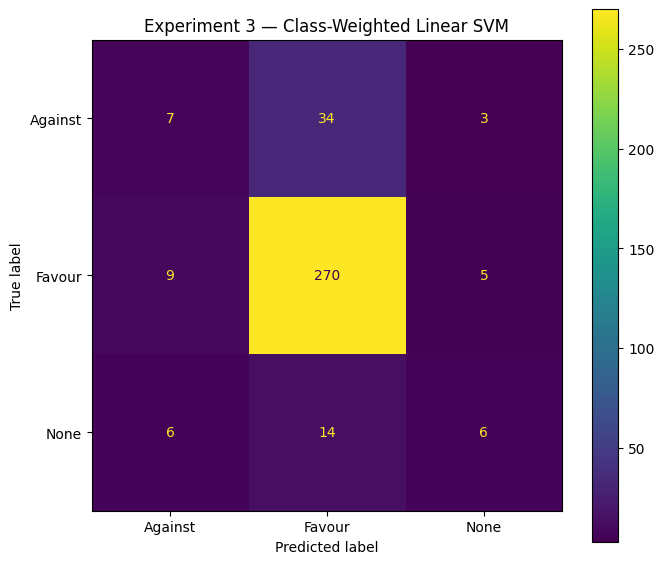


EXPERIMENT 3 COMPLETE
Model: TF-IDF + Class-Weighted Linear SVM
C = 1.0
class_weight = balanced
ngram_range = (1, 2)
max_features = 50,000

Results saved to:
/content/experiment3_class_weighted_svm

IMPORTANT:
Test labels were NOT used for model selection.
We will compare Experiments 1, 2 and 3 using VALIDATION Macro-F1.


In [ ]:
# ============================================================
# EXPERIMENT 3 — TF-IDF + CLASS-WEIGHTED LINEAR SVM
# ONE-CELL COMPLETE VERSION
# ============================================================

# ---------- 1. IMPORTS ----------
import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ---------- 2. UPLOAD DATASETS ----------
print("Upload these 3 files:")
print("1. train(1).csv")
print("2. val(1).csv")
print("3. test(1).csv")
print()

uploaded = files.upload()

# Automatically identify files
train_file = next(
    (f for f in uploaded if f.lower().startswith("train") and f.lower().endswith(".csv")),
    None
)

val_file = next(
    (f for f in uploaded if f.lower().startswith("val") and f.lower().endswith(".csv")),
    None
)

test_file = next(
    (f for f in uploaded if f.lower().startswith("test") and f.lower().endswith(".csv")),
    None
)

if not train_file or not val_file or not test_file:
    raise FileNotFoundError(
        "Could not find all 3 files. Please upload train, val and test CSV files."
    )

# ---------- 3. LOAD DATA ----------
train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

print("\n" + "="*60)
print("DATASET LOADED")
print("="*60)

print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

print("\nColumns:", list(train_df.columns))

# ---------- 4. TEXT PREPROCESSING ----------
def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

X_train_text = train_df["text"].apply(clean_text)
X_val_text   = val_df["text"].apply(clean_text)
X_test_text  = test_df["text"].apply(clean_text)

y_train = train_df["label"]
y_val   = val_df["label"]
y_test  = test_df["label"]

# ---------- 5. TF-IDF ----------
vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_val   = vectorizer.transform(X_val_text)
X_test  = vectorizer.transform(X_test_text)

print("\nTF-IDF:")
print("Training features  :", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features      :", X_test.shape)

# ---------- 6. CLASS-WEIGHTED LINEAR SVM ----------
model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# ---------- 7. VALIDATION PREDICTION ----------
val_pred = model.predict(X_val)

# ---------- 8. METRICS ----------
accuracy = accuracy_score(y_val, val_pred)
macro_f1 = f1_score(y_val, val_pred, average="macro")
weighted_f1 = f1_score(y_val, val_pred, average="weighted")

report = classification_report(
    y_val,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Against", "Favour", "None"],
    output_dict=True,
    zero_division=0
)

# ---------- 9. PRINT RESULTS ----------
print("\n" + "="*60)
print("EXPERIMENT 3 RESULTS")
print("="*60)

print(f"Accuracy    : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1    : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1 : {weighted_f1:.4f} ({weighted_f1*100:.2f}%)")

print("\nClass-wise F1:")
print(f"Against F1 : {report['Against']['f1-score']:.4f} "
      f"({report['Against']['f1-score']*100:.2f}%)")

print(f"Favour F1  : {report['Favour']['f1-score']:.4f} "
      f"({report['Favour']['f1-score']*100:.2f}%)")

print(f"None F1    : {report['None']['f1-score']:.4f} "
      f"({report['None']['f1-score']*100:.2f}%)")

# ---------- 10. FULL CLASSIFICATION REPORT ----------
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)

print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Against", "Favour", "None"],
        digits=4,
        zero_division=0
    )
)

# ---------- 11. CONFUSION MATRIX ----------
cm = confusion_matrix(y_val, val_pred, labels=[0, 1, 2])

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Against", "Favour", "None"]
)

disp.plot(ax=ax, values_format="d")
plt.title("Experiment 3 — Class-Weighted Linear SVM")
plt.tight_layout()
plt.show()

# ---------- 12. SAVE RESULTS ----------
output_dir = "/content/experiment3_class_weighted_svm"
os.makedirs(output_dir, exist_ok=True)

# Validation predictions
pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_val,
    "predicted_label": val_pred
}).to_csv(
    f"{output_dir}/class_weighted_svm_val_predictions.csv",
    index=False
)

# Metrics
pd.DataFrame([{
    "model": "TF-IDF + Class-Weighted Linear SVM",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}]).to_csv(
    f"{output_dir}/class_weighted_svm_validation.csv",
    index=False
)

# Confusion matrix
fig.savefig(
    f"{output_dir}/class_weighted_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# ---------- 13. FINAL ----------
print("\n" + "="*60)
print("EXPERIMENT 3 COMPLETE")
print("="*60)

print("Model: TF-IDF + Class-Weighted Linear SVM")
print("C = 1.0")
print("class_weight = balanced")
print("ngram_range = (1, 2)")
print("max_features = 50,000")

print("\nResults saved to:")
print(output_dir)

print("\nIMPORTANT:")
print("Test labels were NOT used for model selection.")
print("We will compare Experiments 1, 2 and 3 using VALIDATION Macro-F1.")

In [ ]:
# Download Experiment 3 results as a ZIP file

import shutil
from google.colab import files
import os

result_folder = "/content/experiment3_class_weighted_svm"
zip_path = "/content/experiment3_class_weighted_svm"

# Check folder exists
if not os.path.exists(result_folder):
    raise FileNotFoundError(
        "Experiment 3 result folder not found. Run Experiment 3 first."
    )

# Create ZIP
shutil.make_archive(
    zip_path,
    "zip",
    result_folder
)

# Download ZIP
files.download(zip_path + ".zip")

print("✅ Download started!")
print("File: experiment3_class_weighted_svm.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download started!
File: experiment3_class_weighted_svm.zip


Using datasets already loaded in memory.

Dataset sizes:
Train      : (2871, 2)
Validation : (354, 2)
Test       : (355, 2)

Word TF-IDF:
Train: (2871, 12020)
Val  : (354, 12020)

Character TF-IDF:
Train: (2871, 50000)
Val  : (354, 50000)

Combined TF-IDF:
Train: (2871, 62020)
Val  : (354, 62020)
Test : (355, 62020)

EXPERIMENT 4 RESULTS
Accuracy    : 0.7966 (79.66%)
Macro-F1    : 0.4624 (46.24%)
Weighted-F1 : 0.7604 (76.04%)

Class-wise F1:
Against F1 : 0.1515 (15.15%)
Favour F1  : 0.8929 (89.29%)
None F1    : 0.3429 (34.29%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Against     0.2273    0.1136    0.1515        44
      Favour     0.8390    0.9542    0.8929       284
        None     0.6667    0.2308    0.3429        26

    accuracy                         0.7966       354
   macro avg     0.5776    0.4329    0.4624       354
weighted avg     0.7503    0.7966    0.7604       354

Confusion Matrix:
[[  5  38   1]
 [ 11 271   2]
 [  6  14   6]]

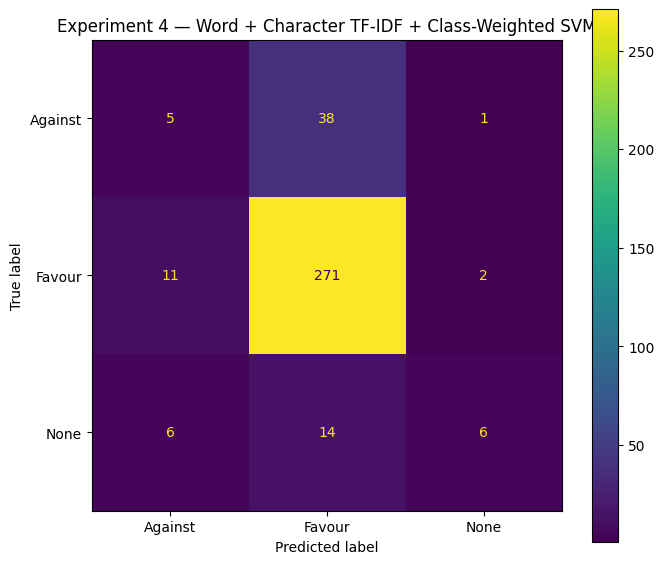


EXPERIMENT 4 COMPLETE
Results saved to:
/content/experiment4_word_char_svm

ZIP file:
/content/experiment4_word_char_svm.zip

IMPORTANT:
Only validation data was used for model comparison.
Test labels were NOT used.


In [ ]:
# ============================================================
# EXPERIMENT 4
# Word + Character TF-IDF + Class-Weighted Linear SVM
# CSET346 - Indic Climate Stance Challenge
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import shutil
import matplotlib.pyplot as plt

from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. LOAD DATA
# ============================================================

# If data already exists in memory, use it.
# Otherwise upload the three CSV files.

try:
    train_df
    val_df
    test_df
    print("Using datasets already loaded in memory.")

except NameError:
    from google.colab import files

    print("Upload train(1).csv, val(1).csv and test(1).csv")
    uploaded = files.upload()

    train_file = next(
        f for f in uploaded
        if f.lower().startswith("train") and f.lower().endswith(".csv")
    )

    val_file = next(
        f for f in uploaded
        if f.lower().startswith("val") and f.lower().endswith(".csv")
    )

    test_file = next(
        f for f in uploaded
        if f.lower().startswith("test") and f.lower().endswith(".csv")
    )

    train_df = pd.read_csv(train_file)
    val_df = pd.read_csv(val_file)
    test_df = pd.read_csv(test_file)

print("\nDataset sizes:")
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

# ============================================================
# 2. PREPROCESSING
# Same basic preprocessing as Experiments 1–3
# ============================================================

def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

X_train_text = train_df["text"].apply(clean_text)
X_val_text   = val_df["text"].apply(clean_text)
X_test_text  = test_df["text"].apply(clean_text)

y_train = train_df["label"]
y_val   = val_df["label"]
y_test  = test_df["label"]

# ============================================================
# 3. WORD-LEVEL TF-IDF
# ============================================================

word_vectorizer = TfidfVectorizer(
    lowercase=True,
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

X_train_word = word_vectorizer.fit_transform(X_train_text)
X_val_word   = word_vectorizer.transform(X_val_text)
X_test_word  = word_vectorizer.transform(X_test_text)

print("\nWord TF-IDF:")
print("Train:", X_train_word.shape)
print("Val  :", X_val_word.shape)

# ============================================================
# 4. CHARACTER-LEVEL TF-IDF
# Character n-grams help with:
# - spelling variations
# - abbreviations
# - hashtags
# - transliteration
# - noisy social-media text
# ============================================================

char_vectorizer = TfidfVectorizer(
    lowercase=True,
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

X_train_char = char_vectorizer.fit_transform(X_train_text)
X_val_char   = char_vectorizer.transform(X_val_text)
X_test_char  = char_vectorizer.transform(X_test_text)

print("\nCharacter TF-IDF:")
print("Train:", X_train_char.shape)
print("Val  :", X_val_char.shape)

# ============================================================
# 5. COMBINE WORD + CHARACTER FEATURES
# ============================================================

X_train = hstack([X_train_word, X_train_char]).tocsr()
X_val   = hstack([X_val_word, X_val_char]).tocsr()
X_test  = hstack([X_test_word, X_test_char]).tocsr()

print("\nCombined TF-IDF:")
print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

# ============================================================
# 6. CLASS-WEIGHTED LINEAR SVM
# Same classifier as Experiment 3
# ============================================================

model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# ============================================================
# 7. VALIDATION PREDICTIONS
# ============================================================

val_pred = model.predict(X_val)

# ============================================================
# 8. METRICS
# ============================================================

accuracy = accuracy_score(y_val, val_pred)

macro_f1 = f1_score(
    y_val,
    val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_val,
    val_pred,
    average="weighted"
)

report = classification_report(
    y_val,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Against", "Favour", "None"],
    output_dict=True,
    zero_division=0
)

# ============================================================
# 9. PRINT RESULTS
# ============================================================

print("\n" + "="*65)
print("EXPERIMENT 4 RESULTS")
print("="*65)

print(f"Accuracy    : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1    : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1 : {weighted_f1:.4f} ({weighted_f1*100:.2f}%)")

print("\nClass-wise F1:")
print(
    f"Against F1 : {report['Against']['f1-score']:.4f} "
    f"({report['Against']['f1-score']*100:.2f}%)"
)

print(
    f"Favour F1  : {report['Favour']['f1-score']:.4f} "
    f"({report['Favour']['f1-score']*100:.2f}%)"
)

print(
    f"None F1    : {report['None']['f1-score']:.4f} "
    f"({report['None']['f1-score']*100:.2f}%)"
)

# ============================================================
# 10. FULL CLASSIFICATION REPORT
# ============================================================

print("\n" + "="*65)
print("CLASSIFICATION REPORT")
print("="*65)

print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Against", "Favour", "None"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_val,
    val_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Against", "Favour", "None"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title("Experiment 4 — Word + Character TF-IDF + Class-Weighted SVM")
plt.tight_layout()

# ============================================================
# 12. SAVE RESULTS
# ============================================================

output_dir = "/content/experiment4_word_char_svm"
os.makedirs(output_dir, exist_ok=True)

# Predictions
pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_val,
    "predicted_label": val_pred
}).to_csv(
    f"{output_dir}/word_char_svm_val_predictions.csv",
    index=False
)

# Metrics
pd.DataFrame([{
    "model": "Word + Character TF-IDF + Class-Weighted Linear SVM",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}]).to_csv(
    f"{output_dir}/word_char_svm_validation.csv",
    index=False
)

# Confusion matrix
fig.savefig(
    f"{output_dir}/word_char_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 13. ZIP RESULTS
# ============================================================

zip_path = shutil.make_archive(
    "/content/experiment4_word_char_svm",
    "zip",
    output_dir
)

print("\n" + "="*65)
print("EXPERIMENT 4 COMPLETE")
print("="*65)

print("Results saved to:")
print(output_dir)

print("\nZIP file:")
print(zip_path)

print("\nIMPORTANT:")
print("Only validation data was used for model comparison.")
print("Test labels were NOT used.")

In [ ]:
from google.colab import files
import os

zip_path = "/content/experiment4_word_char_svm.zip"

if not os.path.exists(zip_path):
    raise FileNotFoundError(
        "Experiment 4 ZIP not found. Run Experiment 4 first."
    )

files.download(zip_path)

print("✅ Download started:")
print("experiment4_word_char_svm.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download started:
experiment4_word_char_svm.zip


In [ ]:
# ============================================================
# EXPERIMENT 5 — XLM-RoBERTa
# Indic Climate Stance Challenge
# ============================================================

!pip -q install transformers accelerate sentencepiece

import os
import re
import shutil
import random
import numpy as np
import pandas as pd
import torch

from google.colab import files

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

# ============================================================
# 1. CHECK GPU
# ============================================================

print("=" * 70)
print("DEVICE CHECK")
print("=" * 70)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

if device == "cpu":
    print("\n⚠️ WARNING: GPU not detected.")
    print("Go to Runtime → Change runtime type → T4 GPU")

# ============================================================
# 2. UPLOAD DATASETS
# ============================================================

print("\nUpload:")
print("1. train(1).csv")
print("2. val(1).csv")
print("3. test(1).csv")

uploaded = files.upload()

train_file = next(
    f for f in uploaded
    if f.lower().startswith("train") and f.lower().endswith(".csv")
)

val_file = next(
    f for f in uploaded
    if f.lower().startswith("val") and f.lower().endswith(".csv")
)

test_file = next(
    f for f in uploaded
    if f.lower().startswith("test") and f.lower().endswith(".csv")
)

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

print("\nDataset sizes:")
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

# ============================================================
# 3. BASIC TEXT CLEANING
# ============================================================

def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

train_df["text"] = train_df["text"].apply(clean_text)
val_df["text"] = val_df["text"].apply(clean_text)
test_df["text"] = test_df["text"].apply(clean_text)

# ============================================================
# 4. LABELS
#
# 0 = Against
# 1 = Favour
# 2 = None
# ============================================================

NUM_LABELS = 3

label_names = {
    0: "Against",
    1: "Favour",
    2: "None"
}

# ============================================================
# 5. XLM-R TOKENIZER
# ============================================================

MODEL_NAME = "xlm-roberta-base"

print("\nLoading tokenizer:", MODEL_NAME)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

MAX_LENGTH = 128

# ============================================================
# 6. DATASET CLASS
# ============================================================

class StanceDataset(Dataset):

    def __init__(self, dataframe, tokenizer, max_length=128):
        self.texts = dataframe["text"].tolist()
        self.labels = dataframe["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length
        )

        encoding["labels"] = self.labels[idx]

        return encoding

train_dataset = StanceDataset(
    train_df,
    tokenizer,
    MAX_LENGTH
)

val_dataset = StanceDataset(
    val_df,
    tokenizer,
    MAX_LENGTH
)

# ============================================================
# 7. MODEL
# ============================================================

print("\nLoading XLM-R model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=label_names,
    label2id={
        "Against": 0,
        "Favour": 1,
        "None": 2
    }
)

# ============================================================
# 8. CLASS WEIGHTS
# Same principle as our best classical baseline
# ============================================================

class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .values
)

class_weights = len(train_df) / (
    NUM_LABELS * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("\nClass counts:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

# ============================================================
# 9. CUSTOM TRAINER WITH CLASS-WEIGHTED LOSS
# ============================================================

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_function(
            logits.view(-1, NUM_LABELS),
            labels.view(-1)
        )

        return (
            (loss, outputs)
            if return_outputs
            else loss
        )

# ============================================================
# 10. METRICS
# ============================================================

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro"
    )

    weighted_f1 = f1_score(
        labels,
        predictions,
        average="weighted"
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1
    }

# ============================================================
# 11. TRAINING SETTINGS
# ============================================================

OUTPUT_DIR = "/content/experiment5_xlmr"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    # Training
    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    learning_rate=2e-5,
    weight_decay=0.01,

    warmup_ratio=0.1,

    # Evaluation
    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    # Logging
    logging_strategy="steps",
    logging_steps=50,

    # Reproducibility
    seed=42,

    # Performance
    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2
)

# ============================================================
# 12. TRAINER
# ============================================================

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    tokenizer=tokenizer,

    data_collator=DataCollatorWithPadding(
        tokenizer=tokenizer
    ),

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=1
        )
    ]
)

# ============================================================
# 13. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("STARTING XLM-R TRAINING")
print("=" * 70)

trainer.train()

# ============================================================
# 14. BEST VALIDATION RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL VALIDATION EVALUATION")
print("=" * 70)

evaluation = trainer.evaluate()

for key, value in evaluation.items():

    if isinstance(value, float):
        print(f"{key}: {value:.4f}")

# ============================================================
# 15. VALIDATION PREDICTIONS
# ============================================================

pred_output = trainer.predict(
    val_dataset
)

val_logits = pred_output.predictions

val_pred = np.argmax(
    val_logits,
    axis=-1
)

# ============================================================
# 16. DETAILED METRICS
# ============================================================

accuracy = accuracy_score(
    val_df["label"],
    val_pred
)

macro_f1 = f1_score(
    val_df["label"],
    val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    val_df["label"],
    val_pred,
    average="weighted"
)

report = classification_report(
    val_df["label"],
    val_pred,
    labels=[0, 1, 2],
    target_names=[
        "Against",
        "Favour",
        "None"
    ],
    output_dict=True,
    zero_division=0
)

print("\n" + "=" * 70)
print("EXPERIMENT 5 RESULTS")
print("=" * 70)

print(
    f"Accuracy    : {accuracy:.4f} "
    f"({accuracy*100:.2f}%)"
)

print(
    f"Macro-F1    : {macro_f1:.4f} "
    f"({macro_f1*100:.2f}%)"
)

print(
    f"Weighted-F1 : {weighted_f1:.4f} "
    f"({weighted_f1*100:.2f}%)"
)

print("\nClass-wise F1:")

print(
    f"Against F1 : "
    f"{report['Against']['f1-score']:.4f} "
    f"({report['Against']['f1-score']*100:.2f}%)"
)

print(
    f"Favour F1  : "
    f"{report['Favour']['f1-score']:.4f} "
    f"({report['Favour']['f1-score']*100:.2f}%)"
)

print(
    f"None F1    : "
    f"{report['None']['f1-score']:.4f} "
    f"({report['None']['f1-score']*100:.2f}%)"
)

# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        val_df["label"],
        val_pred,
        labels=[0, 1, 2],
        target_names=[
            "Against",
            "Favour",
            "None"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    val_df["label"],
    val_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Against",
        "Favour",
        "None"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Experiment 5 — XLM-RoBERTa"
)

plt.tight_layout()

cm_path = (
    "/content/experiment5_xlmr/"
    "xlmr_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 19. SAVE VALIDATION PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({
    "text": val_df["text"],
    "true_label": val_df["label"],
    "predicted_label": val_pred
})

predictions_df.to_csv(
    "/content/experiment5_xlmr/"
    "xlmr_validation_predictions.csv",
    index=False
)

# ============================================================
# 20. SAVE METRICS
# ============================================================

metrics_df = pd.DataFrame([{
    "model": "XLM-RoBERTa",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}])

metrics_df.to_csv(
    "/content/experiment5_xlmr/"
    "xlmr_validation_metrics.csv",
    index=False
)

# ============================================================
# 21. SAVE MODEL + TOKENIZER
# ============================================================

BEST_MODEL_DIR = (
    "/content/experiment5_xlmr/"
    "best_model"
)

trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)

# ============================================================
# 22. ZIP EVERYTHING
# ============================================================

zip_path = shutil.make_archive(
    "/content/experiment5_xlmr_results",
    "zip",
    "/content/experiment5_xlmr"
)

print("\n" + "=" * 70)
print("EXPERIMENT 5 COMPLETE")
print("=" * 70)

print(f"Validation Macro-F1: {macro_f1*100:.2f}%")

print("\nCurrent classical baseline:")
print("Class-Weighted TF-IDF + SVM = 46.97% Macro-F1")

if macro_f1 > 0.4697:
    print("\n🏆 XLM-R BEATS THE CURRENT BASELINE!")
else:
    print("\nXLM-R did not beat the current baseline yet.")

print("\nResults ZIP:")
print(zip_path)

print("\nIMPORTANT:")
print("Test labels were NOT used.")
print("Model selection is based ONLY on validation Macro-F1.")

DEVICE CHECK
Device: cuda

Upload:
1. train(1).csv
2. val(1).csv
3. test(1).csv


Saving val.csv to val.csv
Saving test.csv to test.csv
Saving train.csv to train.csv

Dataset sizes:
Train      : (2871, 2)
Validation : (354, 2)
Test       : (355, 2)

Loading tokenizer: xlm-roberta-base


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Class counts:
[ 308 2294  269]

Class weights:
tensor([3.1071, 0.4172, 3.5576])


TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'

In [ ]:
# ============================================================
# FIX XLM-R EXPERIMENT 5
# Transformers compatibility issue
# ============================================================

!pip -q install -U "transformers==4.44.2" "accelerate>=0.34.0" sentencepiece

import transformers
import accelerate

print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

# ------------------------------------------------------------
# Recreate TrainingArguments
# ------------------------------------------------------------

OUTPUT_DIR = "/content/experiment5_xlmr"

training_args = transformers.TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    learning_rate=2e-5,
    weight_decay=0.01,

    warmup_ratio=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=50,

    seed=42,

    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2
)

print("\n✅ TrainingArguments created successfully!")
print("You can now continue with the Trainer section.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.0/321.0 kB 11.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 109.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.2 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (tokenizers)
Transformers: 5.18.0
Accelerate: 1.15.0


TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'

In [ ]:
# ============================================================
# FIX + START EXPERIMENT 5
# No reinstall required
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import TrainingArguments, Trainer

OUTPUT_DIR = "/content/experiment5_xlmr"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Transformers version:", __import__("transformers").__version__)

# ------------------------------------------------------------
# Training arguments
# warmup_ratio removed because your installed version
# does not support it.
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    learning_rate=2e-5,
    weight_decay=0.01,

    warmup_steps=0,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=50,

    seed=42,

    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2
)

# ------------------------------------------------------------
# Create Trainer
# ------------------------------------------------------------

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    tokenizer=tokenizer,

    data_collator=DataCollatorWithPadding(
        tokenizer=tokenizer
    ),

    compute_metrics=compute_metrics
)

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING EXPERIMENT 5 — XLM-RoBERTa")
print("=" * 70)

trainer.train()

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)

evaluation = trainer.evaluate()

for key, value in evaluation.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

pred_output = trainer.predict(val_dataset)

val_pred = np.argmax(
    pred_output.predictions,
    axis=-1
)

y_true = val_df["label"].values

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

accuracy = accuracy_score(y_true, val_pred)

macro_f1 = f1_score(
    y_true,
    val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_true,
    val_pred,
    average="weighted"
)

report = classification_report(
    y_true,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Against", "Favour", "None"],
    output_dict=True,
    zero_division=0
)

print("\n" + "=" * 70)
print("EXPERIMENT 5 — XLM-R RESULTS")
print("=" * 70)

print(f"Accuracy    : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1    : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1 : {weighted_f1:.4f} ({weighted_f1*100:.2f}%)")

print("\nClass-wise F1:")
print(f"Against : {report['Against']['f1-score']:.4f}")
print(f"Favour  : {report['Favour']['f1-score']:.4f}")
print(f"None    : {report['None']['f1-score']:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Against", "Favour", "None"],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    val_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Against", "Favour", "None"]
).plot(
    ax=ax,
    values_format="d"
)

plt.title("Experiment 5 — XLM-RoBERTa")
plt.tight_layout()

cm_path = f"{OUTPUT_DIR}/xlmr_confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# SAVE PREDICTIONS
# ------------------------------------------------------------

pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_true,
    "predicted_label": val_pred
}).to_csv(
    f"{OUTPUT_DIR}/xlmr_validation_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# SAVE METRICS
# ------------------------------------------------------------

pd.DataFrame([{
    "model": "XLM-RoBERTa",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}]).to_csv(
    f"{OUTPUT_DIR}/xlmr_validation_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# SAVE MODEL
# ------------------------------------------------------------

trainer.save_model(f"{OUTPUT_DIR}/best_model")
tokenizer.save_pretrained(f"{OUTPUT_DIR}/best_model")

# ------------------------------------------------------------
# ZIP RESULTS
# ------------------------------------------------------------

import shutil

zip_path = shutil.make_archive(
    "/content/experiment5_xlmr_results",
    "zip",
    OUTPUT_DIR
)

# ------------------------------------------------------------
# FINAL COMPARISON
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL COMPARISON")
print("=" * 70)

print(f"Current best classical baseline : 46.97% Macro-F1")
print(f"XLM-R validation Macro-F1       : {macro_f1*100:.2f}%")

if macro_f1 > 0.4697:
    print("\n🏆 XLM-R BEATS OUR CLASSICAL BASELINE!")
else:
    print("\nXLM-R is currently below our classical baseline.")

print("\nZIP:", zip_path)

print("\n⚠️ TEST SET WAS NOT USED FOR MODEL SELECTION.")

Transformers version: 5.18.0


TypeError: Trainer.__init__() got an unexpected keyword argument 'tokenizer'

✅ Trainer created successfully!
Starting XLM-R training...



Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,2.101478,1.122460,0.802260,0.297227,0.715359
2,2.017310,0.899041,0.731638,0.529706,0.751459
3,1.650726,0.859128,0.740113,0.526455,0.758220


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


XLM-R VALIDATION RESULTS


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
1.650726,0.899041,3,0.731638,0.529706,0.751459


eval_loss: 0.8990
eval_accuracy: 0.7316
eval_macro_f1: 0.5297
eval_weighted_f1: 0.7515



EXPERIMENT 5 — XLM-R RESULTS
Accuracy    : 0.7316 (73.16%)
Macro-F1    : 0.5297 (52.97%)
Weighted-F1 : 0.7515 (75.15%)

Class-wise F1:
Against F1 : 0.3571 (35.71%)
Favour F1  : 0.8460 (84.60%)
None F1    : 0.3860 (38.60%)

Classification Report:
              precision    recall  f1-score   support

     Against     0.2941    0.4545    0.3571        44
      Favour     0.8941    0.8028    0.8460       284
        None     0.3548    0.4231    0.3860        26

    accuracy                         0.7316       354
   macro avg     0.5144    0.5601    0.5297       354
weighted avg     0.7799    0.7316    0.7515       354

Confusion Matrix:
[[ 20  21   3]
 [ 39 228  17]
 [  9   6  11]]


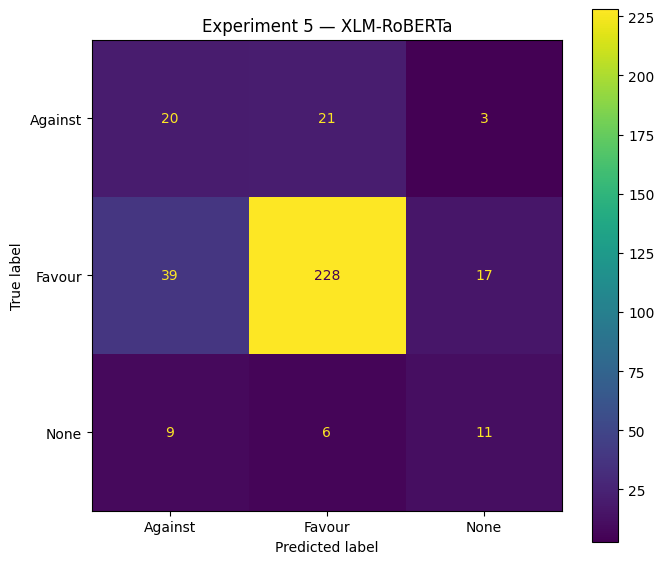

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


EXPERIMENT 5 COMPLETE
XLM-R Macro-F1       : 52.97%
Current SVM baseline : 46.97%

🏆 XLM-R BEATS OUR CLASSICAL BASELINE!

Results ZIP:
/content/experiment5_xlmr_results.zip

⚠️ TEST SET WAS NOT USED.


In [ ]:
# ============================================================
# FIX XLM-R TRAINER FOR TRANSFORMERS 5.18
# ============================================================

# Recreate Trainer using processing_class instead of tokenizer

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    # Transformers 5.x uses processing_class
    processing_class=tokenizer,

    data_collator=DataCollatorWithPadding(
        tokenizer=tokenizer
    ),

    compute_metrics=compute_metrics
)

print("✅ Trainer created successfully!")
print("Starting XLM-R training...\n")

# ============================================================
# TRAIN
# ============================================================

trainer.train()

# ============================================================
# VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("XLM-R VALIDATION RESULTS")
print("=" * 70)

evaluation = trainer.evaluate()

for key, value in evaluation.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")

# ============================================================
# PREDICTIONS
# ============================================================

pred_output = trainer.predict(val_dataset)

val_pred = np.argmax(
    pred_output.predictions,
    axis=-1
)

y_true = val_df["label"].values

# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    val_pred
)

macro_f1 = f1_score(
    y_true,
    val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_true,
    val_pred,
    average="weighted"
)

report = classification_report(
    y_true,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Against", "Favour", "None"],
    output_dict=True,
    zero_division=0
)

print("\n" + "=" * 70)
print("EXPERIMENT 5 — XLM-R RESULTS")
print("=" * 70)

print(f"Accuracy    : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro-F1    : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Weighted-F1 : {weighted_f1:.4f} ({weighted_f1*100:.2f}%)")

print("\nClass-wise F1:")
print(f"Against F1 : {report['Against']['f1-score']:.4f} "
      f"({report['Against']['f1-score']*100:.2f}%)")

print(f"Favour F1  : {report['Favour']['f1-score']:.4f} "
      f"({report['Favour']['f1-score']*100:.2f}%)")

print(f"None F1    : {report['None']['f1-score']:.4f} "
      f"({report['None']['f1-score']*100:.2f}%)")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Against", "Favour", "None"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    val_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Against", "Favour", "None"]
).plot(
    ax=ax,
    values_format="d"
)

plt.title("Experiment 5 — XLM-RoBERTa")
plt.tight_layout()

cm_path = "/content/experiment5_xlmr/xlmr_confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# SAVE RESULTS
# ============================================================

OUTPUT_DIR = "/content/experiment5_xlmr"
os.makedirs(OUTPUT_DIR, exist_ok=True)

pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_true,
    "predicted_label": val_pred
}).to_csv(
    f"{OUTPUT_DIR}/xlmr_validation_predictions.csv",
    index=False
)

pd.DataFrame([{
    "model": "XLM-RoBERTa",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "weighted_f1": weighted_f1,
    "against_f1": report["Against"]["f1-score"],
    "favour_f1": report["Favour"]["f1-score"],
    "none_f1": report["None"]["f1-score"]
}]).to_csv(
    f"{OUTPUT_DIR}/xlmr_validation_metrics.csv",
    index=False
)

# Save best model
trainer.save_model(f"{OUTPUT_DIR}/best_model")
tokenizer.save_pretrained(f"{OUTPUT_DIR}/best_model")

# ============================================================
# ZIP
# ============================================================

import shutil

zip_path = shutil.make_archive(
    "/content/experiment5_xlmr_results",
    "zip",
    OUTPUT_DIR
)

print("\n" + "=" * 70)
print("EXPERIMENT 5 COMPLETE")
print("=" * 70)

print(f"XLM-R Macro-F1       : {macro_f1*100:.2f}%")
print(f"Current SVM baseline : 46.97%")

if macro_f1 > 0.4697:
    print("\n🏆 XLM-R BEATS OUR CLASSICAL BASELINE!")
else:
    print("\nXLM-R has NOT beaten our classical baseline yet.")

print("\nResults ZIP:")
print(zip_path)

print("\n⚠️ TEST SET WAS NOT USED.")

In [ ]:
import os
import zipfile
from google.colab import files

result_dir = "/content/experiment5_xlmr"
small_zip = "/content/experiment5_results_only.zip"

files_to_include = [
    "xlmr_validation_metrics.csv",
    "xlmr_validation_predictions.csv",
    "xlmr_confusion_matrix.png"
]

with zipfile.ZipFile(small_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in files_to_include:
        path = os.path.join(result_dir, filename)

        if os.path.exists(path):
            z.write(path, arcname=filename)
        else:
            print("Not found:", filename)

print("Creating small results ZIP...")

files.download(small_zip)

print("✅ Download started:")
print("experiment5_results_only.zip")

Creating small results ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download started:
experiment5_results_only.zip


DEVICE CHECK
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

Using datasets already loaded in memory.

Dataset sizes:
Train      : (2871, 2)
Validation : (354, 2)
Test       : (355, 2)

Loading: google/muril-base-cased


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]


Loading MuRIL model...


... (11 outputs left out)


MuRIL VALIDATION


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Weighted F1
1.990559,1.062621,3,0.788136,0.401804,0.736901


eval_loss: 1.0626
eval_accuracy: 0.7881
eval_macro_f1: 0.4018
eval_weighted_f1: 0.7369



EXPERIMENT 6 — MuRIL RESULTS
Accuracy    : 0.7881 (78.81%)
Macro-F1    : 0.4018 (40.18%)
Weighted-F1 : 0.7369 (73.69%)

Class-wise F1:
Against F1 : 0.0000 (0.00%)
Favour F1  : 0.8896 (88.96%)
None F1    : 0.3158 (31.58%)

Classification Report:
              precision    recall  f1-score   support

     Against     0.0000    0.0000    0.0000        44
      Favour     0.8359    0.9507    0.8896       284
        None     0.2903    0.3462    0.3158        26

    accuracy                         0.7881       354
   macro avg     0.3754    0.4323    0.4018       354
weighted avg     0.6919    0.7881    0.7369       354

Confusion Matrix:
[[  0  36   8]
 [  0 270  14]
 [  0  17   9]]


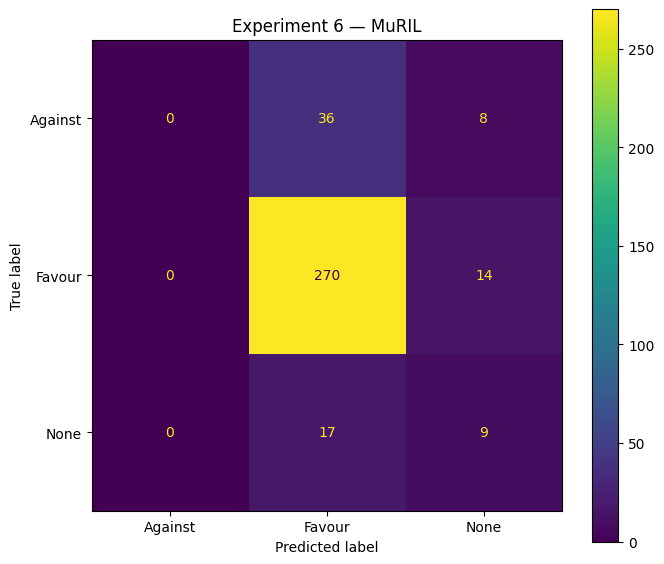

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINAL COMPARISON
Classical SVM : 46.97% Macro-F1
XLM-R         : 52.97% Macro-F1
MuRIL         : 40.18% Macro-F1

MuRIL is below our current best models.

Results ZIP:
/content/experiment6_muril_results_only.zip

⚠️ TEST SET WAS NOT USED.


In [ ]:
# ============================================================
# EXPERIMENT 6 — MuRIL
# Indic Climate Stance Challenge
# ============================================================

import os
import re
import shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

# ============================================================
# 1. GPU CHECK
# ============================================================

print("=" * 70)
print("DEVICE CHECK")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU NOT DETECTED — use Colab T4 GPU.")

# ============================================================
# 2. LOAD DATA
# ============================================================

try:
    train_df
    val_df
    test_df
    print("\nUsing datasets already loaded in memory.")

except NameError:

    print("\nUpload:")
    print("1. train(1).csv")
    print("2. val(1).csv")
    print("3. test(1).csv")

    uploaded = files.upload()

    train_file = next(
        f for f in uploaded
        if f.lower().startswith("train") and f.lower().endswith(".csv")
    )

    val_file = next(
        f for f in uploaded
        if f.lower().startswith("val") and f.lower().endswith(".csv")
    )

    test_file = next(
        f for f in uploaded
        if f.lower().startswith("test") and f.lower().endswith(".csv")
    )

    train_df = pd.read_csv(train_file)
    val_df = pd.read_csv(val_file)
    test_df = pd.read_csv(test_file)

print("\nDataset sizes:")
print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

# ============================================================
# 3. TEXT CLEANING
# ============================================================

def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+|https\S+",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

train_df["text"] = train_df["text"].apply(clean_text)
val_df["text"] = val_df["text"].apply(clean_text)
test_df["text"] = test_df["text"].apply(clean_text)

# ============================================================
# 4. LABELS
# ============================================================

# 0 = Against
# 1 = Favour
# 2 = None

NUM_LABELS = 3

id2label = {
    0: "Against",
    1: "Favour",
    2: "None"
}

label2id = {
    "Against": 0,
    "Favour": 1,
    "None": 2
}

# ============================================================
# 5. MuRIL
# ============================================================

MODEL_NAME = "google/muril-base-cased"

print("\nLoading:", MODEL_NAME)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

MAX_LENGTH = 128

# ============================================================
# 6. DATASET
# ============================================================

class StanceDataset(Dataset):

    def __init__(
        self,
        dataframe,
        tokenizer,
        max_length=128
    ):

        self.texts = dataframe["text"].tolist()

        self.labels = (
            dataframe["label"]
            .astype(int)
            .tolist()
        )

        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length
        )

        encoding["labels"] = self.labels[idx]

        return encoding

train_dataset = StanceDataset(
    train_df,
    tokenizer,
    MAX_LENGTH
)

val_dataset = StanceDataset(
    val_df,
    tokenizer,
    MAX_LENGTH
)

# ============================================================
# 7. MODEL
# ============================================================

print("\nLoading MuRIL model...")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id
)

# ============================================================
# 8. CLASS WEIGHTS
# ============================================================

class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .values
)

class_weights = (
    len(train_df)
    /
    (NUM_LABELS * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("\nClass counts:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

# ============================================================
# 9. WEIGHTED TRAINER
# ============================================================

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(
                logits.device
            )
        )

        loss = loss_function(
            logits.view(-1, NUM_LABELS),
            labels.view(-1)
        )

        if return_outputs:
            return loss, outputs

        return loss

# ============================================================
# 10. METRICS
# ============================================================

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        ),

        "weighted_f1": f1_score(
            labels,
            predictions,
            average="weighted"
        )
    }

# ============================================================
# 11. TRAINING CONFIG
# Compatible with Transformers 5.x
# ============================================================

OUTPUT_DIR = "/content/experiment6_muril"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    gradient_accumulation_steps=2,

    learning_rate=2e-5,

    weight_decay=0.01,

    warmup_steps=0,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=50,

    seed=42,

    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2
)

# ============================================================
# 12. TRAINER
# ============================================================

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    processing_class=tokenizer,

    data_collator=DataCollatorWithPadding(
        tokenizer=tokenizer
    ),

    compute_metrics=compute_metrics
)

# ============================================================
# 13. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("STARTING EXPERIMENT 6 — MuRIL")
print("=" * 70)

trainer.train()

# ============================================================
# 14. VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("MuRIL VALIDATION")
print("=" * 70)

evaluation = trainer.evaluate()

for key, value in evaluation.items():

    if isinstance(value, float):
        print(
            f"{key}: {value:.4f}"
        )

# ============================================================
# 15. PREDICTIONS
# ============================================================

prediction_output = trainer.predict(
    val_dataset
)

val_pred = np.argmax(
    prediction_output.predictions,
    axis=-1
)

y_true = val_df["label"].values

# ============================================================
# 16. FINAL METRICS
# ============================================================

accuracy = accuracy_score(
    y_true,
    val_pred
)

macro_f1 = f1_score(
    y_true,
    val_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_true,
    val_pred,
    average="weighted"
)

report = classification_report(
    y_true,
    val_pred,

    labels=[
        0,
        1,
        2
    ],

    target_names=[
        "Against",
        "Favour",
        "None"
    ],

    output_dict=True,

    zero_division=0
)

# ============================================================
# 17. PRINT RESULTS
# ============================================================

print("\n" + "=" * 70)
print("EXPERIMENT 6 — MuRIL RESULTS")
print("=" * 70)

print(
    f"Accuracy    : {accuracy:.4f} "
    f"({accuracy*100:.2f}%)"
)

print(
    f"Macro-F1    : {macro_f1:.4f} "
    f"({macro_f1*100:.2f}%)"
)

print(
    f"Weighted-F1 : {weighted_f1:.4f} "
    f"({weighted_f1*100:.2f}%)"
)

print("\nClass-wise F1:")

print(
    f"Against F1 : "
    f"{report['Against']['f1-score']:.4f} "
    f"({report['Against']['f1-score']*100:.2f}%)"
)

print(
    f"Favour F1  : "
    f"{report['Favour']['f1-score']:.4f} "
    f"({report['Favour']['f1-score']*100:.2f}%)"
)

print(
    f"None F1    : "
    f"{report['None']['f1-score']:.4f} "
    f"({report['None']['f1-score']*100:.2f}%)"
)

# ============================================================
# 18. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        val_pred,

        labels=[
            0,
            1,
            2
        ],

        target_names=[
            "Against",
            "Favour",
            "None"
        ],

        digits=4,

        zero_division=0
    )
)

# ============================================================
# 19. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    val_pred,

    labels=[
        0,
        1,
        2
    ]
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,

    display_labels=[
        "Against",
        "Favour",
        "None"
    ]
).plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "Experiment 6 — MuRIL"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/muril_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 20. SAVE PREDICTIONS
# ============================================================

pd.DataFrame({
    "text": val_df["text"],
    "true_label": y_true,
    "predicted_label": val_pred
}).to_csv(
    f"{OUTPUT_DIR}/muril_validation_predictions.csv",
    index=False
)

# ============================================================
# 21. SAVE METRICS
# ============================================================

pd.DataFrame([{

    "model":
        "MuRIL + Class-Weighted Loss",

    "accuracy":
        accuracy,

    "macro_f1":
        macro_f1,

    "weighted_f1":
        weighted_f1,

    "against_f1":
        report["Against"]["f1-score"],

    "favour_f1":
        report["Favour"]["f1-score"],

    "none_f1":
        report["None"]["f1-score"]

}]).to_csv(
    f"{OUTPUT_DIR}/muril_validation_metrics.csv",
    index=False
)

# ============================================================
# 22. SAVE MODEL
# ============================================================

trainer.save_model(
    f"{OUTPUT_DIR}/best_model"
)

tokenizer.save_pretrained(
    f"{OUTPUT_DIR}/best_model"
)

# ============================================================
# 23. CREATE SMALL RESULTS ZIP
# Do NOT include model weights in the upload ZIP.
# ============================================================

small_zip = (
    "/content/"
    "experiment6_muril_results_only.zip"
)

import zipfile

with zipfile.ZipFile(
    small_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for filename in [
        "muril_validation_metrics.csv",
        "muril_validation_predictions.csv",
        "muril_confusion_matrix.png"
    ]:

        path = os.path.join(
            OUTPUT_DIR,
            filename
        )

        if os.path.exists(path):

            z.write(
                path,
                arcname=filename
            )

# ============================================================
# 24. FINAL COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("FINAL COMPARISON")
print("=" * 70)

print(
    f"Classical SVM : 46.97% Macro-F1"
)

print(
    f"XLM-R         : 52.97% Macro-F1"
)

print(
    f"MuRIL         : {macro_f1*100:.2f}% Macro-F1"
)

if macro_f1 > 0.5297:

    print(
        "\n🏆 MuRIL BEATS XLM-R!"
    )

elif macro_f1 > 0.4697:

    print(
        "\n✅ MuRIL beats the classical baseline "
        "but does not beat XLM-R."
    )

else:

    print(
        "\nMuRIL is below our current best models."
    )

print(
    "\nResults ZIP:"
)

print(small_zip)

print(
    "\n⚠️ TEST SET WAS NOT USED."
)